# TREASURE: One-month forecasting of SPI3, SPEI3 and Q_Disp

NeuralProphet models with hidden layers and only lagged regressors, compared against ARIMA, SARIMA, linear AR, persistence, and climatology.

## 1. Data, models, and hyperparameter tuning

Set `RUN_TUNING = False`, if you don't want train the models

In [ ]:
from pathlib import Path
from itertools import product
import json, os, platform, random, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import neuralprophet
from neuralprophet import NeuralProphet, set_log_level
from scipy.stats import pearsonr
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from IPython.display import display
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tools.sm_exceptions import ConvergenceWarning
import subprocess, sys
from scipy.stats import gamma, norm
from sklearn.ensemble import RandomForestRegressor
from statsmodels.stats.proportion import proportion_confint
from scipy.stats import t as stats_t

set_log_level('ERROR')
warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=UserWarning)

if not hasattr(np, "NaN"):
    np.NaN = np.nan

DATA_DIR = Path("..") / "Dataset" 
OUT = Path("..") / 'Results_Forecasting' 
OUT.mkdir(parents=True, exist_ok=True)

RUN_TUNING = False         
TUNING_SEED = 42
TRAIN_RATIO, VAL_RATIO = 0.70, 0.15

Data = pd.read_excel(DATA_DIR / 'Full_Dataset.xlsx', '3 months')
Data5 = pd.read_excel(DATA_DIR / 'Idro_Dataset.xlsx')

CLIMATE_REGRESSORS = ['Precipitation', 'Actual Evotranspiration', 'Run-OFF',
                      'Mean Temperature', 'Potential Evotranspiration']
SPECS = {
    'SPI3':   dict(raw=Data,  target='SPI',    regressors=CLIMATE_REGRESSORS),
    'SPEI3':  dict(raw=Data,  target='SPEI',   regressors=CLIMATE_REGRESSORS),
    'Q_Disp': dict(raw=Data5, target='Q_Disp', regressors=['Q_tronto', 'Precipitation']),
}

CLIMATE_GRID = dict(n_lags=[3, 6, 12], hidden=[[8], [16], [16, 16]],
                    learning_rate=[0.001, 0.01], yearly=[False, True], growth=['off'])
HYDRO_GRID = dict(n_lags=[3, 6, 12], hidden=[[2], [4]],
                  learning_rate=[0.001, 0.01], yearly=[False, True], growth=['off'])
GRID = {'SPI3': CLIMATE_GRID, 'SPEI3': CLIMATE_GRID, 'Q_Disp': HYDRO_GRID}
EPOCHS = {'SPI3': 100, 'SPEI3': 100, 'Q_Disp': 200}


def set_seed(seed):
    os.environ['PYTHONHASHSEED'] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def prepare_monthly(raw, target, regressors):
    df = raw[['Date', target] + regressors].rename(columns={'Date': 'ds', target: 'y'})
    df['ds'] = pd.to_datetime(df['ds']).dt.to_period('M').dt.to_timestamp()
    df = df.sort_values('ds').reset_index(drop=True)
    expected = pd.date_range(df['ds'].min(), df['ds'].max(), freq='MS')
    if len(df) != len(expected) or not (df['ds'].values == expected.values).all():
        raise ValueError(f'{target}: mesi mancanti o duplicati')
    if df.drop(columns='ds').isna().any().any():
        raise ValueError(f'{target}: valori mancanti')
    return df


def chronological_split(df):
    a = int(len(df) * TRAIN_RATIO)
    b = int(len(df) * (TRAIN_RATIO + VAL_RATIO))
    return df.iloc[:a].copy(), df.iloc[a:b].copy(), df.iloc[b:].copy()


def build_model(cfg, regressors, epochs):
    model = NeuralProphet(
        growth=cfg['growth'],
        yearly_seasonality=bool(cfg['yearly']),
        weekly_seasonality=False,
        daily_seasonality=False,
        n_lags=int(cfg['n_lags']),
        n_forecasts=1,
        ar_layers=list(cfg['hidden']),
        lagged_reg_layers=list(cfg['hidden']),
        learning_rate=float(cfg['learning_rate']),
        epochs=int(epochs),
    )
    model.add_lagged_regressor(names=regressors, n_lags=int(cfg['n_lags']))
    return model


def fit_model(target, df_fit, cfg, seed):
    set_seed(seed)
    model = build_model(cfg, SPECS[target]['regressors'], EPOCHS[target])
    model.fit(df_fit, freq='MS', progress=None)
    for net in (model.model.ar_net, model.model.covar_net):
        n_linear = sum(isinstance(layer, torch.nn.Linear) for layer in net)
        assert n_linear >= 2, 'Il modello non ha strati nascosti'
    return model


def one_step_forecast(model, df):
    fc = model.predict(df)
    fc['ds'] = pd.to_datetime(fc['ds'])
    return fc.set_index('ds')['yhat1'].dropna()


def compute_metrics(obs, pred):
    obs, pred = np.asarray(obs, float), np.asarray(pred, float)
    return dict(N=len(obs),
                RMSE=float(np.sqrt(mean_squared_error(obs, pred))),
                MAE=float(mean_absolute_error(obs, pred)),
                R2=float(r2_score(obs, pred)),
                Pearson_r=float(pearsonr(obs, pred)[0]),
                Bias=float(np.mean(pred - obs)))


def count_parameters(model):
    return int(sum(p.numel() for p in model.model.parameters() if p.requires_grad))


DATASETS = {name: prepare_monthly(s['raw'], s['target'], s['regressors']) for name, s in SPECS.items()}

partitions = []
for name, df in DATASETS.items():
    for label, part in zip(['Training', 'Validation', 'Test'], chronological_split(df)):
        partitions.append(dict(Target=name, Partition=label, Start=part.ds.min().date(),
                               End=part.ds.max().date(), N=len(part)))
partition_table = pd.DataFrame(partitions)
partition_table.to_csv(OUT / 'Partitions.csv', index=False)
display(partition_table)

SEARCH_FILE = OUT / 'Hyperparameter_search.csv'
if RUN_TUNING:
    rows = []
    for target, grid in GRID.items():
        train, val, _ = chronological_split(DATASETS[target])
        combos = list(product(*grid.values()))
        for i, values in enumerate(combos, 1):
            cfg = dict(zip(grid.keys(), values))
            start = time.time()
            model = fit_model(target, train, cfg, TUNING_SEED)
            pred = one_step_forecast(model, pd.concat([train, val])).reindex(val.ds)
            result = compute_metrics(val.y, pred)
            rows.append(dict(Target=target, n_lags=cfg['n_lags'], hidden=json.dumps(cfg['hidden']),
                             learning_rate=cfg['learning_rate'], yearly=cfg['yearly'],
                             growth=cfg['growth'], epochs=EPOCHS[target],
                             Trainable_parameters=count_parameters(model),
                             Training_samples=len(train) - cfg['n_lags'],
                             Val_RMSE=result['RMSE'], Val_MAE=result['MAE'],
                             Val_R2=result['R2'], Val_r=result['Pearson_r']))
            print(f'{target} {i}/{len(combos)} | {cfg} | Val RMSE {result["RMSE"]:.3f} | {time.time()-start:.0f} s')
    search_table = pd.DataFrame(rows)
    search_table.to_csv(SEARCH_FILE, index=False)
else:
    search_table = pd.read_csv(SEARCH_FILE)

search_table['Eligible'] = search_table.Trainable_parameters < search_table.Training_samples
search_table = search_table.sort_values(['Target', 'Eligible', 'Val_RMSE', 'Val_MAE'],
                                        ascending=[True, False, True, True]).reset_index(drop=True)
assert search_table.groupby('Target').Eligible.any().all(), 'Nessun modello ammissibile'
selected_table = (search_table[search_table.Eligible].groupby('Target', sort=False).first()
                  .reindex(list(SPECS)).reset_index())
BEST = {row.Target: dict(n_lags=int(row.n_lags), hidden=json.loads(row.hidden),
                         learning_rate=float(row.learning_rate), yearly=bool(row.yearly),
                         growth=row.growth)
        for row in selected_table.itertuples()}
display(selected_table)


c:\Users\MacGy\AppData\Local\Programs\Python\Python312\Lib\site-packages\lightning_fabric\__init__.py:29: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  __import__("pkg_resources").declare_namespace(__name__)
Importing plotly failed. Interactive plots will not work.
Importing plotly failed. Interactive plots will not work.


,Target,Partition,Start,End,N
0,SPI3,Training,1952-01-01,2001-08-01,596
1,SPI3,Validation,2001-09-01,2012-04-01,128
2,SPI3,Test,2012-05-01,2022-12-01,128
3,SPEI3,Training,1952-01-01,2001-08-01,596
4,SPEI3,Validation,2001-09-01,2012-04-01,128
5,SPEI3,Test,2012-05-01,2022-12-01,128
6,Q_Disp,Training,2013-01-01,2019-12-01,84
7,Q_Disp,Validation,2020-01-01,2021-06-01,18
8,Q_Disp,Test,2021-07-01,2022-12-01,18


SPI3 1/36 | {'n_lags': 3, 'hidden': [8], 'learning_rate': 0.001, 'yearly': False, 'growth': 'off'} | Val RMSE 0.778 | 11 s
SPI3 2/36 | {'n_lags': 3, 'hidden': [8], 'learning_rate': 0.001, 'yearly': True, 'growth': 'off'} | Val RMSE 1.041 | 7 s
SPI3 3/36 | {'n_lags': 3, 'hidden': [8], 'learning_rate': 0.01, 'yearly': False, 'growth': 'off'} | Val RMSE 0.633 | 6 s
SPI3 4/36 | {'n_lags': 3, 'hidden': [8], 'learning_rate': 0.01, 'yearly': True, 'growth': 'off'} | Val RMSE 0.615 | 7 s
SPI3 5/36 | {'n_lags': 3, 'hidden': [16], 'learning_rate': 0.001, 'yearly': False, 'growth': 'off'} | Val RMSE 0.738 | 7 s
SPI3 6/36 | {'n_lags': 3, 'hidden': [16], 'learning_rate': 0.001, 'yearly': True, 'growth': 'off'} | Val RMSE 1.041 | 9 s
SPI3 7/36 | {'n_lags': 3, 'hidden': [16], 'learning_rate': 0.01, 'yearly': False, 'growth': 'off'} | Val RMSE 0.638 | 8 s
SPI3 8/36 | {'n_lags': 3, 'hidden': [16], 'learning_rate': 0.01, 'yearly': True, 'growth': 'off'} | Val RMSE 0.649 | 8 s
SPI3 9/36 | {'n_lags': 3, '

,Target,n_lags,hidden,learning_rate,yearly,growth,epochs,Trainable_parameters,Training_samples,Val_RMSE,Val_MAE,Val_R2,Val_r,Eligible
0,SPI3,3,[8],0.01,True,off,100,189,593,0.615219,0.491848,0.697362,0.837646,True
1,SPEI3,3,[8],0.01,True,off,100,189,593,0.607389,0.504515,0.725659,0.855752,True
2,Q_Disp,3,[4],0.01,False,off,200,53,81,3.414300,2.816520,0.672932,0.871904,True


## 2. Rolling origin + validation

The configuration for each method is selected using an expanding window approach with retraining at each origin. Criterion: mean RMSE across folds. The test set is not used.
Set `RUN_ROLLING_SELECTION = False`, if you want read results

In [ ]:


warnings.filterwarnings('ignore', category=ConvergenceWarning)

RUN_ROLLING_SELECTION = False   
SELECTION_FILE = OUT / 'Rolling_selection.json'

TOP_K_NEURAL = 5
DEV_FOLDS = {'SPI3': (5, 24), 'SPEI3': (5, 24), 'Q_Disp': (3, 12)}  
LINEAR_AR_LAGS = [3, 6, 12]
LINEAR_AR_LR = 0.01
ARIMA_ORDERS = [(1, 0, 0), (2, 0, 0), (3, 0, 0), (1, 0, 1), (2, 0, 1), (1, 0, 2), (1, 1, 1)]
SARIMA_ORDERS = [(1, 0, 0), (1, 0, 1), (2, 0, 1)]
SARIMA_SEASONAL = [(1, 0, 0, 12), (1, 0, 1, 12), (0, 1, 1, 12)]
METHODS = ['NeuralProphet', 'Linear AR', 'ARIMA', 'SARIMA', 'Persistence', 'Monthly climatology']
STOCHASTIC = {'NeuralProphet', 'Linear AR'}

def fit_linear_ar(target, df_fit, cfg, seed):
    set_seed(seed)
    model = NeuralProphet(growth='off', yearly_seasonality=False, weekly_seasonality=False,
                          daily_seasonality=False, n_lags=int(cfg['n_lags']), n_forecasts=1,
                          ar_layers=[], learning_rate=LINEAR_AR_LR, epochs=EPOCHS[target])
    model.fit(df_fit[['ds', 'y']], freq='MS', progress=None)
    return model


def forecast_sarimax(df_fit, df_predict, order, seasonal=(0, 0, 0, 0)):
    order, seasonal = tuple(order), tuple(seasonal)
    y_all = pd.Series(df_predict.y.values, index=pd.DatetimeIndex(df_predict.ds, freq='MS'))
    n_fit = len(df_fit)
    trend = 'c' if order[1] == 0 and seasonal[1] == 0 else 'n'
    result = SARIMAX(y_all.iloc[:n_fit], order=order, seasonal_order=seasonal,
                     trend=trend).fit(disp=False, maxiter=200)
    return result.apply(y_all, refit=False).predict(start=n_fit, end=len(y_all) - 1)


def forecast_method(method, target, cfg, df_fit, df_predict, seed):
    if method == 'NeuralProphet':
        pred = one_step_forecast(fit_model(target, df_fit, cfg, seed), df_predict)
    elif method == 'Linear AR':
        pred = one_step_forecast(fit_linear_ar(target, df_fit, cfg, seed), df_predict[['ds', 'y']])
    elif method == 'ARIMA':
        pred = forecast_sarimax(df_fit, df_predict, cfg['order'])
    elif method == 'SARIMA':
        pred = forecast_sarimax(df_fit, df_predict, cfg['order'], cfg['seasonal'])
    elif method == 'Persistence':
        pred = df_predict.set_index('ds').y.shift(1)
    elif method == 'Monthly climatology':
        monthly_mean = df_fit.groupby(df_fit.ds.dt.month).y.mean()
        pred = pd.Series(df_predict.ds.dt.month.map(monthly_mean).values, index=df_predict.ds)
    else:
        raise ValueError(method)
    return pred[pred.index > df_fit.ds.max()]


def evaluate_folds(method, target, cfg, df, folds, seeds):
    rows = []
    for fold, (a, b) in enumerate(folds, 1):
        for seed in (seeds if method in STOCHASTIC else seeds[:1]):
            pred = forecast_method(method, target, cfg, df.iloc[:a], df.iloc[:b], seed)
            part = df.iloc[a:b]
            pred = pred.reindex(part.ds)
            assert pred.notna().all(), f'{method}: previsioni mancanti'
            rows += [dict(Target=target, Method=method, Fold=fold, Seed=seed, ds=d,
                          Observed=float(o), Predicted=float(p))
                     for d, o, p in zip(part.ds, part.y, pred)]
    return pd.DataFrame(rows)


def candidate_configs(target, min_train):
    table = search_table[(search_table.Target == target) & search_table.Eligible]
    table = table[table.Trainable_parameters < min_train - table.n_lags].head(TOP_K_NEURAL)
    assert len(table), f'{target}: nessun modello neurale ammissibile per il fold piu corto'
    neural = [dict(n_lags=int(r.n_lags), hidden=json.loads(r.hidden), learning_rate=float(r.learning_rate),
                   yearly=bool(r.yearly), growth=r.growth) for r in table.itertuples()]
    return {'NeuralProphet': neural,
            'Linear AR': [dict(n_lags=lag) for lag in LINEAR_AR_LAGS],
            'ARIMA': [dict(order=order) for order in ARIMA_ORDERS],
            'SARIMA': [dict(order=o, seasonal=s) for o, s in product(SARIMA_ORDERS, SARIMA_SEASONAL)],
            'Persistence': [{}], 'Monthly climatology': [{}]}


if RUN_ROLLING_SELECTION:
    selection_rows, fold_rows = [], []
    for target in SPECS:
        train, val, _ = chronological_split(DATASETS[target])
        dev = pd.concat([train, val]).reset_index(drop=True)
        n_folds, horizon = DEV_FOLDS[target]
        folds = [(len(dev) - (n_folds - i) * horizon, len(dev) - (n_folds - i - 1) * horizon) for i in range(n_folds)]
        for method, configs in candidate_configs(target, folds[0][0]).items():
            for cfg in configs:
                start = time.time()
                try:
                    pred = evaluate_folds(method, target, cfg, dev, folds, [TUNING_SEED])
                except (ValueError, np.linalg.LinAlgError) as error:
                    print(f'{target} | {method} | {cfg}: scartato ({error})')
                    continue
                by_fold = [compute_metrics(g.Observed, g.Predicted) | dict(Fold=f) for f, g in pred.groupby('Fold')]
                fold_rows += [dict(Target=target, Method=method, Config=json.dumps(cfg), **m) for m in by_fold]
                rmse = [m['RMSE'] for m in by_fold]
                selection_rows.append(dict(Target=target, Method=method, Config=json.dumps(cfg),
                                           Folds=n_folds, Months_per_fold=horizon,
                                           RMSE_mean=float(np.mean(rmse)), RMSE_sd=float(np.std(rmse, ddof=1)),
                                           MAE_mean=float(np.mean([m['MAE'] for m in by_fold]))))
                print(f'{target} | {method} | {cfg} | RMSE {np.mean(rmse):.3f} | {time.time()-start:.0f} s')
    rolling_folds = pd.DataFrame(fold_rows)
    rolling_summary = pd.DataFrame(selection_rows).sort_values(['Target', 'Method', 'RMSE_mean']).reset_index(drop=True)
    rolling_folds.to_csv(OUT / 'Rolling_selection_folds.csv', index=False)
    rolling_summary.to_csv(OUT / 'Rolling_selection_summary.csv', index=False)
    best_rows = rolling_summary.groupby(['Target', 'Method'], sort=False).first().reset_index()
    BEST_BY_METHOD = {t: {r.Method: json.loads(r.Config) for r in best_rows[best_rows.Target == t].itertuples()}
                      for t in SPECS}
    SELECTION_FILE.write_text(json.dumps(BEST_BY_METHOD, indent=2), encoding='utf-8')
else:
    rolling_summary = pd.read_csv(OUT / 'Rolling_selection_summary.csv')
    BEST_BY_METHOD = json.loads(SELECTION_FILE.read_text(encoding='utf-8'))

BEST = {t: BEST_BY_METHOD[t]['NeuralProphet'] for t in SPECS}
final_rows = []
for t, cfg in BEST.items():
    row = search_table[(search_table.Target == t) & (search_table.n_lags == cfg['n_lags'])
                       & (search_table.hidden == json.dumps(cfg['hidden']))
                       & (search_table.learning_rate == cfg['learning_rate'])
                       & (search_table.yearly == cfg['yearly']) & (search_table.growth == cfg['growth'])].iloc[0]
    rolling_row = rolling_summary[(rolling_summary.Target == t) & (rolling_summary.Method == 'NeuralProphet')
                                  & (rolling_summary.Config == json.dumps(cfg))].iloc[0]
    final_rows.append(row.to_dict() | dict(Rolling_RMSE_mean=rolling_row.RMSE_mean, Rolling_RMSE_sd=rolling_row.RMSE_sd))
selected_table = pd.DataFrame(final_rows)

selected_methods = (rolling_summary.sort_values('RMSE_mean').groupby(['Target', 'Method'], sort=False).first()
                    .reset_index().sort_values(['Target', 'RMSE_mean']).reset_index(drop=True))
selected_methods.to_csv(OUT / 'Rolling_selected_methods.csv', index=False)
print('Rolling origin su training + validazione: configurazione scelta per ogni metodo')
display(selected_methods.round(3))

SPI3 | NeuralProphet | {'n_lags': 3, 'hidden': [8], 'learning_rate': 0.01, 'yearly': True, 'growth': 'off'} | RMSE 0.607 | 62 s
SPI3 | NeuralProphet | {'n_lags': 3, 'hidden': [8], 'learning_rate': 0.01, 'yearly': False, 'growth': 'off'} | RMSE 0.630 | 68 s
SPI3 | NeuralProphet | {'n_lags': 6, 'hidden': [8], 'learning_rate': 0.01, 'yearly': True, 'growth': 'off'} | RMSE 0.654 | 79 s
SPI3 | NeuralProphet | {'n_lags': 3, 'hidden': [16], 'learning_rate': 0.01, 'yearly': False, 'growth': 'off'} | RMSE 0.619 | 71 s
SPI3 | NeuralProphet | {'n_lags': 3, 'hidden': [16], 'learning_rate': 0.01, 'yearly': True, 'growth': 'off'} | RMSE 0.641 | 65 s
SPI3 | Linear AR | {'n_lags': 3} | RMSE 0.747 | 16 s
SPI3 | Linear AR | {'n_lags': 6} | RMSE 0.737 | 20 s
SPI3 | Linear AR | {'n_lags': 12} | RMSE 0.699 | 48 s
SPI3 | ARIMA | {'order': (1, 0, 0)} | RMSE 0.765 | 0 s
SPI3 | ARIMA | {'order': (2, 0, 0)} | RMSE 0.754 | 0 s
SPI3 | ARIMA | {'order': (3, 0, 0)} | RMSE 0.746 | 0 s
SPI3 | ARIMA | {'order': (1, 0,

,Target,Method,Config,Folds,Months_per_fold,RMSE_mean,RMSE_sd,MAE_mean
0,Q_Disp,NeuralProphet,"{""n_lags"": 3, ""hidden"": [4], ""learning_rate"": ...",3,12,3.576,0.532,2.887
1,Q_Disp,SARIMA,"{""order"": [2, 0, 1], ""seasonal"": [1, 0, 1, 12]}",3,12,3.701,0.516,2.920
2,Q_Disp,ARIMA,"{""order"": [1, 0, 2]}",3,12,3.820,0.348,3.160
3,Q_Disp,Linear AR,"{""n_lags"": 3}",3,12,3.848,0.305,3.140
4,Q_Disp,Persistence,{},3,12,4.515,0.858,3.343
5,Q_Disp,Monthly climatology,{},3,12,6.463,1.144,5.422
6,SPEI3,NeuralProphet,"{""n_lags"": 3, ""hidden"": [8], ""learning_rate"": ...",5,24,0.616,0.082,0.514
7,SPEI3,Linear AR,"{""n_lags"": 12}",5,24,0.768,0.142,0.609
8,SPEI3,ARIMA,"{""order"": [1, 0, 2]}",5,24,0.775,0.165,0.617
9,SPEI3,SARIMA,"{""order"": [1, 0, 1], ""seasonal"": [1, 0, 0, 12]}",5,24,0.784,0.122,0.647


## 3. Seed reproducibility and training with multiple seeds

In [ ]:
SEEDS = [42, 123, 2026, 7, 1234]

repro_rows = []
for target, cfg in BEST.items():
    df = DATASETS[target]
    train, _, _ = chronological_split(df)
    run_1 = one_step_forecast(fit_model(target, train, cfg, SEEDS[0]), df)
    run_2 = one_step_forecast(fit_model(target, train, cfg, SEEDS[0]), df)
    max_difference = float((run_1 - run_2).abs().max())
    repro_rows.append(dict(Target=target, Seed=SEEDS[0], Max_abs_difference=max_difference,
                           Reproducible=max_difference < 1e-6))
reproducibility_table = pd.DataFrame(repro_rows)
reproducibility_table.to_csv(OUT / 'Seed_reproducibility.csv', index=False)
display(reproducibility_table)
assert reproducibility_table.Reproducible.all(), 'Stesso seed, risultati diversi'

leak_rows = []
for target, cfg in BEST.items():
    df = DATASETS[target]
    train, _, test = chronological_split(df)
    model = fit_model(target, train, cfg, SEEDS[0])
    month = test.ds.iloc[0]
    base = one_step_forecast(model, df)
    altered = df.copy()
    columns = ['y'] + SPECS[target]['regressors']
    altered.loc[altered.ds == month, columns] = altered.loc[altered.ds == month, columns] + 100
    changed = one_step_forecast(model, altered)
    next_month = month + pd.DateOffset(months=1)
    leak_rows.append(dict(Target=target, Month=month.date(),
                          Change_same_month=abs(changed[month] - base[month]),
                          Change_next_month=abs(changed[next_month] - base[next_month])))
leakage_table = pd.DataFrame(leak_rows)
leakage_table.to_csv(OUT / 'Leakage_check.csv', index=False)
display(leakage_table)
assert (leakage_table.Change_same_month < 1e-6).all(), 'Il mese target entra nella previsione'
assert (leakage_table.Change_next_month > 0).all(), 'Il mese precedente non viene usato'

metric_rows, prediction_rows = [], []
for target, cfg in BEST.items():
    df = DATASETS[target]
    train, val, test = chronological_split(df)
    for seed in SEEDS:
        model_a = fit_model(target, train, cfg, seed)
        pred_a = one_step_forecast(model_a, df)
        model_b = fit_model(target, pd.concat([train, val]), cfg, seed)
        pred_b = one_step_forecast(model_b, df)
        for label, part, pred in [('Training', train, pred_a), ('Validation', val, pred_a), ('Test', test, pred_b)]:
            part_pred = pred.reindex(part.ds).dropna()
            observed = part.set_index('ds').y.loc[part_pred.index]
            metric_rows.append(dict(Target=target, Partition=label, Seed=seed,
                                    Trainable_parameters=count_parameters(model_b),
                                    **compute_metrics(observed, part_pred)))
            prediction_rows += [dict(Target=target, Partition=label, Seed=seed, ds=d,
                                     Observed=float(observed[d]), Predicted=float(part_pred[d]))
                                for d in part_pred.index]
        print(f'{target} | seed {seed} completato')

seed_metrics = pd.DataFrame(metric_rows)
predictions = pd.DataFrame(prediction_rows)
seed_metrics.to_csv(OUT / 'Metrics_by_seed.csv', index=False)
predictions.to_csv(OUT / 'Predictions_by_seed.csv', index=False)


,Target,Seed,Max_abs_difference,Reproducible
0,SPI3,42,0.0,True
1,SPEI3,42,0.0,True
2,Q_Disp,42,0.0,True


,Target,Month,Change_same_month,Change_next_month
0,SPI3,2012-05-01,0.0,55.410312
1,SPEI3,2012-05-01,0.0,41.478398
2,Q_Disp,2021-07-01,0.0,92.155123


SPI3 | seed 42 completato
SPI3 | seed 123 completato
SPI3 | seed 2026 completato
SPI3 | seed 7 completato
SPI3 | seed 1234 completato
SPEI3 | seed 42 completato
SPEI3 | seed 123 completato
SPEI3 | seed 2026 completato
SPEI3 | seed 7 completato
SPEI3 | seed 1234 completato
Q_Disp | seed 42 completato
Q_Disp | seed 123 completato
Q_Disp | seed 2026 completato
Q_Disp | seed 7 completato
Q_Disp | seed 1234 completato


## 4. Independent test and rolling origin on the test set


In [ ]:
ROBUST_SEEDS = SEEDS[:3]
TEST_REFIT_MONTHS = {'SPI3': 12, 'SPEI3': 12, 'Q_Disp': 6}

test_frames = [predictions[(predictions.Partition == 'Test')].assign(Method='NeuralProphet', Fold=1)
               .drop(columns='Partition')]
for target in SPECS:
    df = DATASETS[target]
    test_start = len(df) - len(chronological_split(df)[2])
    for method in METHODS[1:]:
        test_frames.append(evaluate_folds(method, target, BEST_BY_METHOD[target][method], df,
                                          [(test_start, len(df))], SEEDS))
        print(f'Test indipendente | {target} | {method} completato')
independent_predictions = pd.concat(test_frames, ignore_index=True)

rolling_frames = []
for target in SPECS:
    df = DATASETS[target]
    test_start = len(df) - len(chronological_split(df)[2])
    step = TEST_REFIT_MONTHS[target]
    folds = [(a, min(a + step, len(df))) for a in range(test_start, len(df), step)]
    for method in METHODS:
        rolling_frames.append(evaluate_folds(method, target, BEST_BY_METHOD[target][method], df, folds, ROBUST_SEEDS))
        print(f'Rolling sul test | {target} | {method} completato')
rolling_predictions = pd.concat(rolling_frames, ignore_index=True)


def comparison_table(pred, label):
    """Metriche per seed, poi media e SD; skill = 1 - RMSE / RMSE di riferimento."""
    per_seed = pd.DataFrame([dict(Target=t, Method=m, Seed=s, **compute_metrics(g.Observed, g.Predicted))
                             for (t, m, s), g in pred.groupby(['Target', 'Method', 'Seed'], sort=False)])
    table = (per_seed.groupby(['Target', 'Method'], sort=False)
             .agg(N=('N', 'first'), N_seeds=('Seed', 'nunique'), RMSE_mean=('RMSE', 'mean'), RMSE_sd=('RMSE', 'std'),
                  MAE_mean=('MAE', 'mean'), MAE_sd=('MAE', 'std'), R2_mean=('R2', 'mean'), R2_sd=('R2', 'std'),
                  r_mean=('Pearson_r', 'mean'), r_sd=('Pearson_r', 'std'),
                  Bias_mean=('Bias', 'mean'), Bias_sd=('Bias', 'std')).reset_index())
    for reference, name in [('Persistence', 'Skill_vs_persistence'), ('Monthly climatology', 'Skill_vs_climatology')]:
        ref = table[table.Method == reference].set_index('Target').RMSE_mean
        table[name] = 1 - table.RMSE_mean / table.Target.map(ref)
    table.insert(2, 'Evaluation', label)
    return table, per_seed


independent_comparison, independent_by_seed = comparison_table(independent_predictions, 'Independent test')
rolling_comparison, rolling_by_seed = comparison_table(rolling_predictions, 'Rolling origin on test')
rolling_fold_rmse = pd.DataFrame([dict(Target=t, Method=m, Fold=f, RMSE=compute_metrics(g.Observed, g.Predicted)['RMSE'])
                                  for (t, m, f), g in rolling_predictions.groupby(['Target', 'Method', 'Fold'], sort=False)])

for frame, name in [(independent_predictions, 'Independent_test_predictions'), (independent_by_seed, 'Independent_test_by_seed'),
                    (independent_comparison, 'Independent_test_comparison'), (rolling_predictions, 'Rolling_test_predictions'),
                    (rolling_by_seed, 'Rolling_test_by_seed'), (rolling_comparison, 'Rolling_test_comparison'),
                    (rolling_fold_rmse, 'Rolling_test_fold_RMSE')]:
    frame.to_csv(OUT / f'{name}.csv', index=False)
print('Calcolo completato: i risultati si leggono nelle due celle successive.')


Test indipendente | SPI3 | Linear AR completato
Test indipendente | SPI3 | ARIMA completato
Test indipendente | SPI3 | SARIMA completato
Test indipendente | SPI3 | Persistence completato
Test indipendente | SPI3 | Monthly climatology completato
Test indipendente | SPEI3 | Linear AR completato
Test indipendente | SPEI3 | ARIMA completato
Test indipendente | SPEI3 | SARIMA completato
Test indipendente | SPEI3 | Persistence completato
Test indipendente | SPEI3 | Monthly climatology completato
Test indipendente | Q_Disp | Linear AR completato
Test indipendente | Q_Disp | ARIMA completato
Test indipendente | Q_Disp | SARIMA completato
Test indipendente | Q_Disp | Persistence completato
Test indipendente | Q_Disp | Monthly climatology completato
Rolling sul test | SPI3 | NeuralProphet completato
Rolling sul test | SPI3 | Linear AR completato
Rolling sul test | SPI3 | ARIMA completato
Rolling sul test | SPI3 | SARIMA completato
Rolling sul test | SPI3 | Persistence completato
Rolling sul test

## 5. NeuralProphet: predicted vs. observed and tables

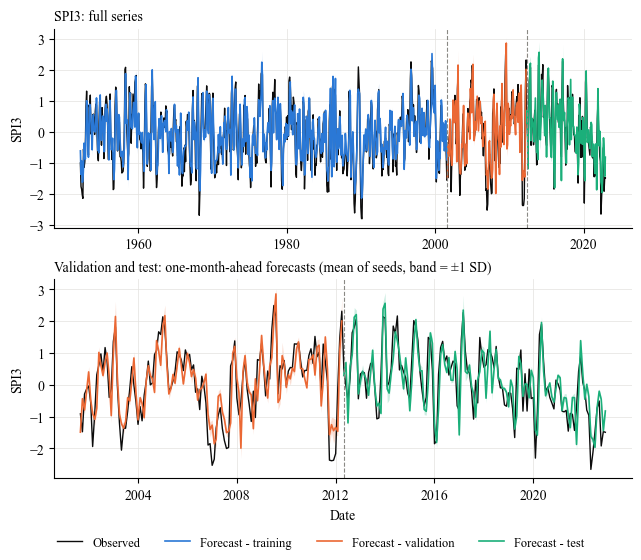

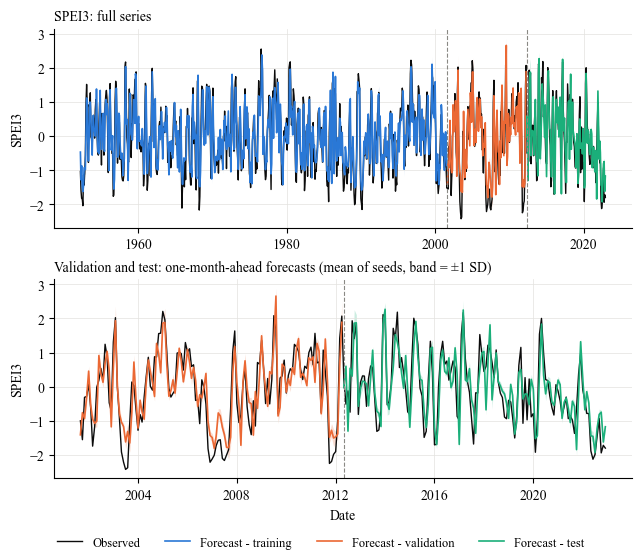

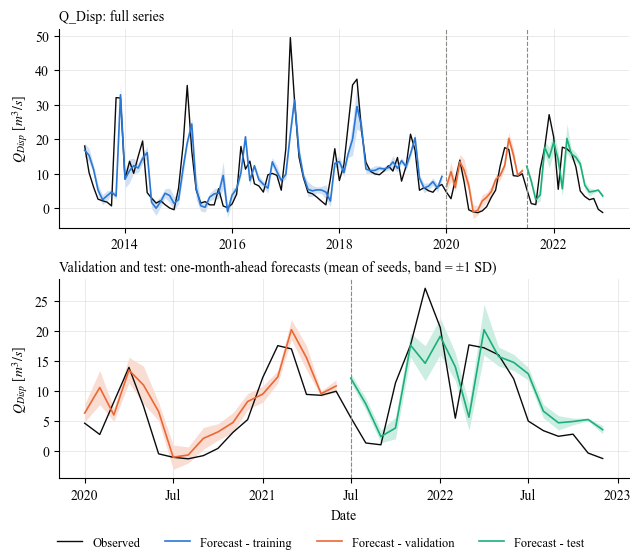

Iperparametri selezionati


,Target,n_lags,hidden,learning_rate,yearly,growth,epochs,Trainable_parameters,Training_samples,Val_RMSE,...,Eligible,Rolling_RMSE_mean,Rolling_RMSE_sd,Regressors,Regressor_type,n_forecasts,Tuning_seed,NeuralProphet,PyTorch,Python
0,SPI3,3,[8],0.01,True,off,100,189,593,0.615219,...,True,0.606584,0.132939,Precipitation; Actual Evotranspiration; Run-OF...,lagged only,1,42,0.8.0,2.9.0+cpu,3.12.10
1,SPEI3,3,[8],0.01,True,off,100,189,593,0.607389,...,True,0.616300,0.082320,Precipitation; Actual Evotranspiration; Run-OF...,lagged only,1,42,0.8.0,2.9.0+cpu,3.12.10
2,Q_Disp,3,[4],0.01,False,off,200,53,81,3.414300,...,True,3.576480,0.531857,Q_tronto; Precipitation,lagged only,1,42,0.8.0,2.9.0+cpu,3.12.10


Ricerca completa (ordinata per RMSE di validazione)


,Target,n_lags,hidden,learning_rate,yearly,growth,epochs,Trainable_parameters,Training_samples,Val_RMSE,Val_MAE,Val_R2,Val_r,Eligible
0,Q_Disp,3,[4],0.010,False,off,200,53,81,3.414300,2.816520,0.672932,0.871904,True
1,Q_Disp,3,[2],0.010,False,off,200,27,81,3.678118,3.111136,0.620435,0.823486,True
2,Q_Disp,3,[4],0.001,False,off,200,53,81,3.692128,3.253268,0.617538,0.862930,True
3,Q_Disp,3,[2],0.001,True,off,200,39,81,4.710445,3.819837,0.377473,0.756192,True
4,Q_Disp,3,[2],0.010,True,off,200,39,81,4.786353,3.840865,0.357247,0.764568,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
91,SPI3,6,[16],0.001,True,off,100,653,590,0.845871,0.661536,0.427900,0.700557,False
92,SPI3,3,"[16, 16]",0.001,True,off,100,909,593,0.901858,0.717065,0.349661,0.694462,False
93,SPI3,12,"[16, 16]",0.001,True,off,100,1773,584,0.909838,0.705323,0.338101,0.653138,False
94,SPI3,12,[8],0.001,True,off,100,621,584,0.967468,0.773187,0.251595,0.665808,False


Test: un risultato per seed


,Target,Seed,Trainable_parameters,N,RMSE,MAE,R2,Pearson_r,Bias
0,SPI3,42,189,128,0.599,0.498,0.666,0.823,0.031
1,SPI3,123,189,128,0.623,0.507,0.639,0.810,0.014
2,SPI3,2026,189,128,0.620,0.493,0.643,0.805,-0.026
3,SPI3,7,189,128,0.590,0.484,0.676,0.828,-0.002
4,SPI3,1234,189,128,0.614,0.505,0.650,0.815,-0.015
5,SPEI3,42,189,128,0.603,0.495,0.672,0.821,0.029
6,SPEI3,123,189,128,0.634,0.517,0.637,0.806,0.009
7,SPEI3,2026,189,128,0.614,0.499,0.659,0.813,0.028
8,SPEI3,7,189,128,0.604,0.497,0.671,0.820,0.005
9,SPEI3,1234,189,128,0.629,0.511,0.643,0.807,-0.002


Test: media e deviazione standard tra seed


,Target,N,N_seeds,Trainable_parameters,RMSE_mean,RMSE_sd,MAE_mean,MAE_sd,R2_mean,R2_sd,r_mean,r_sd,Bias_mean,Bias_sd
0,SPI3,128,5,189,0.609,0.014,0.497,0.010,0.655,0.016,0.816,0.009,0.001,0.023
1,SPEI3,128,5,189,0.617,0.014,0.504,0.010,0.656,0.016,0.814,0.007,0.014,0.014
2,Q_Disp,18,5,53,6.347,0.388,5.186,0.353,0.401,0.073,0.659,0.048,1.154,0.187


Tutte le partizioni: media e deviazione standard tra seed


,Target,Partition,N,N_seeds,Trainable_parameters,RMSE_mean,RMSE_sd,MAE_mean,MAE_sd,R2_mean,R2_sd,r_mean,r_sd,Bias_mean,Bias_sd
0,SPI3,Training,593,5,189,0.507,0.013,0.401,0.011,0.704,0.016,0.839,0.009,-0.010,0.005
1,SPI3,Validation,128,5,189,0.629,0.009,0.499,0.007,0.684,0.009,0.829,0.006,0.001,0.054
2,SPI3,Test,128,5,189,0.609,0.014,0.497,0.010,0.655,0.016,0.816,0.009,0.001,0.023
3,SPEI3,Training,593,5,189,0.523,0.010,0.414,0.010,0.695,0.012,0.834,0.007,-0.014,0.004
4,SPEI3,Validation,128,5,189,0.619,0.011,0.510,0.013,0.715,0.010,0.847,0.007,0.031,0.049
5,SPEI3,Test,128,5,189,0.617,0.014,0.504,0.010,0.656,0.016,0.814,0.007,0.014,0.014
6,Q_Disp,Training,81,5,53,6.629,0.204,4.261,0.286,0.556,0.027,0.748,0.018,-0.536,0.147
7,Q_Disp,Validation,18,5,53,3.967,0.498,3.132,0.499,0.553,0.113,0.816,0.042,1.717,0.412
8,Q_Disp,Test,18,5,53,6.347,0.388,5.186,0.353,0.401,0.073,0.659,0.048,1.154,0.187


File salvati in C:\Users\MacGy\Downloads\Treasure\Dati italia\Revisione\Results_Forecasting


In [ ]:
cm = 1 / 2.54
plt.rcParams.update({'font.family': 'Times New Roman', 'font.size': 10, 'axes.labelsize': 10,
                     'axes.titlesize': 10, 'xtick.labelsize': 10, 'ytick.labelsize': 10,
                     'legend.fontsize': 9, 'mathtext.fontset': 'stix'})
COLORS = {'Training': '#2a78d6', 'Validation': '#eb6834', 'Test': '#1baf7a', 'Observed': '#0b0b0b'}
UNITS = {'SPI3': 'SPI3', 'SPEI3': 'SPEI3', 'Q_Disp': r'$Q_{Disp}$ [$m^3/s$]'}
PARTITIONS = ['Training', 'Validation', 'Test']

ensemble = (predictions.groupby(['Target', 'Partition', 'ds'], as_index=False)
            .agg(Observed=('Observed', 'first'), Mean=('Predicted', 'mean'), SD=('Predicted', 'std')))

def draw_panel(ax, target, parts):
    data = ensemble[(ensemble.Target == target) & (ensemble.Partition.isin(parts))].sort_values('ds')
    observed = data.drop_duplicates('ds')
    ax.plot(observed.ds, observed.Observed, color=COLORS['Observed'], lw=1.0, label='Observed')
    for part in parts:
        g = data[data.Partition == part]
        ax.fill_between(g.ds, g.Mean - g.SD, g.Mean + g.SD, color=COLORS[part], alpha=0.22, lw=0)
        ax.plot(g.ds, g.Mean, color=COLORS[part], lw=1.2, label=f'Forecast - {part.lower()}')
    for part in parts[1:]:
        ax.axvline(data[data.Partition == part].ds.min(), color='#8a8984', ls='--', lw=0.8)
    ax.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=8))
    ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(ax.xaxis.get_major_locator()))
    ax.set_ylabel(UNITS[target])
    ax.grid(color='#e3e2de', lw=0.5)
    ax.spines[['top', 'right']].set_visible(False)

for target in SPECS:
    fig, axes = plt.subplots(2, 1, figsize=(16 * cm, 14 * cm), constrained_layout=True)
    draw_panel(axes[0], target, PARTITIONS)
    axes[0].set_title(f'{target}: full series', loc='left')
    draw_panel(axes[1], target, ['Validation', 'Test'])
    axes[1].set_title('Validation and test: one-month-ahead forecasts (mean of seeds, band = ±1 SD)', loc='left')
    axes[1].set_xlabel('Date')
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc='outside lower center', ncol=4, frameon=False)
    fig.savefig(OUT / f'{target}_forecast_vs_observed.pdf', bbox_inches='tight')
    fig.savefig(OUT / f'{target}_forecast_vs_observed.png', dpi=300, bbox_inches='tight')
    plt.show()

summary = (seed_metrics.groupby(['Target', 'Partition'], sort=False)
           .agg(N=('N', 'first'), N_seeds=('Seed', 'nunique'), Trainable_parameters=('Trainable_parameters', 'first'),
                RMSE_mean=('RMSE', 'mean'), RMSE_sd=('RMSE', 'std'), MAE_mean=('MAE', 'mean'), MAE_sd=('MAE', 'std'),
                R2_mean=('R2', 'mean'), R2_sd=('R2', 'std'), r_mean=('Pearson_r', 'mean'), r_sd=('Pearson_r', 'std'),
                Bias_mean=('Bias', 'mean'), Bias_sd=('Bias', 'std')).reset_index())
summary.to_csv(OUT / 'Metrics_summary.csv', index=False)

test_by_seed = seed_metrics[seed_metrics.Partition == 'Test'].drop(columns='Partition').reset_index(drop=True)
test_by_seed.to_csv(OUT / 'Test_metrics_by_seed.csv', index=False)
test_summary = summary[summary.Partition == 'Test'].drop(columns='Partition').reset_index(drop=True)
test_summary.to_csv(OUT / 'Test_metrics_summary.csv', index=False)

selected_final = selected_table.assign(
    Regressors=selected_table.Target.map(lambda t: '; '.join(SPECS[t]['regressors'])),
    Regressor_type='lagged only', n_forecasts=1, Tuning_seed=TUNING_SEED,
    NeuralProphet=neuralprophet.__version__, PyTorch=torch.__version__, Python=platform.python_version())
selected_final.to_csv(OUT / 'Hyperparameter_selected.csv', index=False)

print('Iperparametri selezionati'); display(selected_final)
print('Ricerca completa (ordinata per RMSE di validazione)'); display(search_table)
print('Test: un risultato per seed'); display(test_by_seed.round(3))
print('Test: media e deviazione standard tra seed'); display(test_summary.round(3))
print('Tutte le partizioni: media e deviazione standard tra seed'); display(summary.round(3))
print('File salvati in', OUT.resolve())


## 6. Comparison of the methods

Test indipendente


,Target,Method,Evaluation,N,N_seeds,RMSE_mean,RMSE_sd,MAE_mean,MAE_sd,R2_mean,R2_sd,r_mean,r_sd,Bias_mean,Bias_sd,Skill_vs_persistence,Skill_vs_climatology
0,Q_Disp,SARIMA,Independent test,18,1,5.868,NaN,4.604,NaN,0.490,NaN,0.701,NaN,0.259,NaN,0.107,0.183
1,Q_Disp,ARIMA,Independent test,18,1,5.900,NaN,5.048,NaN,0.484,NaN,0.700,NaN,0.503,NaN,0.102,0.179
2,Q_Disp,Linear AR,Independent test,18,5,6.056,0.272,4.818,0.295,0.456,0.050,0.683,0.025,0.207,0.414,0.078,0.157
3,Q_Disp,NeuralProphet,Independent test,18,5,6.347,0.388,5.186,0.353,0.401,0.073,0.659,0.048,1.154,0.187,0.034,0.117
4,Q_Disp,Persistence,Independent test,18,1,6.569,NaN,4.924,NaN,0.361,NaN,0.668,NaN,0.623,NaN,0.000,0.086
5,Q_Disp,Monthly climatology,Independent test,18,1,7.186,NaN,5.140,NaN,0.235,NaN,0.502,NaN,-0.807,NaN,-0.094,0.000
6,SPEI3,NeuralProphet,Independent test,128,5,0.617,0.014,0.504,0.010,0.656,0.016,0.814,0.007,0.014,0.014,0.365,0.423
7,SPEI3,ARIMA,Independent test,128,1,0.809,NaN,0.611,NaN,0.409,NaN,0.660,NaN,0.014,NaN,0.167,0.243
8,SPEI3,Linear AR,Independent test,128,5,0.836,0.032,0.641,0.030,0.369,0.049,0.639,0.024,0.013,0.018,0.140,0.218
9,SPEI3,SARIMA,Independent test,128,1,0.853,NaN,0.663,NaN,0.343,NaN,0.598,NaN,0.021,NaN,0.122,0.202


Rolling origin sul test


,Target,Method,Evaluation,N,N_seeds,RMSE_mean,RMSE_sd,MAE_mean,MAE_sd,R2_mean,R2_sd,r_mean,r_sd,Bias_mean,Bias_sd,Skill_vs_persistence,Skill_vs_climatology
0,Q_Disp,SARIMA,Rolling origin on test,18,1,5.929,NaN,4.670,NaN,0.479,NaN,0.693,NaN,0.315,NaN,0.097,0.203
1,Q_Disp,ARIMA,Rolling origin on test,18,1,5.971,NaN,5.149,NaN,0.472,NaN,0.692,NaN,0.611,NaN,0.091,0.198
2,Q_Disp,NeuralProphet,Rolling origin on test,18,3,6.189,0.305,4.896,0.315,0.431,0.057,0.672,0.039,0.995,0.164,0.058,0.168
3,Q_Disp,Linear AR,Rolling origin on test,18,3,6.277,0.406,5.005,0.390,0.414,0.077,0.656,0.039,0.558,0.747,0.044,0.157
4,Q_Disp,Persistence,Rolling origin on test,18,1,6.569,NaN,4.924,NaN,0.361,NaN,0.668,NaN,0.623,NaN,0.000,0.117
5,Q_Disp,Monthly climatology,Rolling origin on test,18,1,7.442,NaN,5.326,NaN,0.179,NaN,0.453,NaN,-0.624,NaN,-0.133,0.000
6,SPEI3,NeuralProphet,Rolling origin on test,128,3,0.600,0.012,0.486,0.010,0.676,0.013,0.825,0.009,0.034,0.014,0.383,0.439
7,SPEI3,ARIMA,Rolling origin on test,128,1,0.807,NaN,0.614,NaN,0.412,NaN,0.657,NaN,0.023,NaN,0.169,0.245
8,SPEI3,Linear AR,Rolling origin on test,128,3,0.839,0.038,0.650,0.035,0.363,0.059,0.632,0.028,0.023,0.018,0.136,0.215
9,SPEI3,SARIMA,Rolling origin on test,128,1,0.855,NaN,0.667,NaN,0.340,NaN,0.593,NaN,0.028,NaN,0.120,0.200


Rolling origin sul test: RMSE medio per fold


Fold                           1      2      3      4      5      6      7   \
Target Method                                                                 
Q_Disp ARIMA                6.651  6.619  4.347    NaN    NaN    NaN    NaN   
       Linear AR            7.123  6.741  4.730    NaN    NaN    NaN    NaN   
       Monthly climatology  8.607  6.750  6.819    NaN    NaN    NaN    NaN   
       NeuralProphet        7.236  6.654  4.298    NaN    NaN    NaN    NaN   
       Persistence          6.753  8.556  3.263    NaN    NaN    NaN    NaN   
       SARIMA               6.702  6.553  4.196    NaN    NaN    NaN    NaN   
SPEI3  ARIMA                1.064  1.008  0.775  0.729  0.793  0.819  0.545   
       Linear AR            1.104  1.105  0.794  0.815  0.859  0.791  0.611   
       Monthly climatology  0.976  1.086  1.321  1.120  1.075  0.941  0.770   
       NeuralProphet        0.836  0.472  0.689  0.502  0.592  0.732  0.479   
       Persistence          1.320  1.209  0.962  1.156  0.987  0.810  0.516   
       SARIMA               1.155  0.931  0.900  0.937  0.851  0.760  0.495   
SPI3   ARIMA                0.772  0.774  0.725  0.770  0.744  0.924  0.532   
       Linear AR            0.837  0.857  0.729  0.815  0.824  0.841  0.630   
       Monthly climatology  1.002  1.053  1.332  1.144  1.097  0.824  0.766   
       NeuralProphet        0.469  0.553  0.599  0.658  0.548  0.685  0.458   
       Persistence          1.076  1.009  0.840  1.180  0.909  0.836  0.513   
       SARIMA               0.883  0.773  0.839  0.900  0.800  0.831  0.523   

Fold                           8      9      10     11  
Target Method                                           
Q_Disp ARIMA                  NaN    NaN    NaN    NaN  
       Linear AR              NaN    NaN    NaN    NaN  
       Monthly climatology    NaN    NaN    NaN    NaN  
       NeuralProphet          NaN    NaN    NaN    NaN  
       Persistence            NaN    NaN    NaN    NaN  
       SARIMA                 NaN    NaN    NaN    NaN  
SPEI3  ARIMA                1.123  0.321  0.511  0.819  
       Linear AR            1.132  0.389  0.523  0.723  
       Monthly climatology  1.047  0.790  0.794  1.766  
       NeuralProphet        0.654  0.308  0.559  0.595  
       Persistence          1.361  0.528  0.576  0.603  
       SARIMA               1.200  0.396  0.539  0.848  
SPI3   ARIMA                1.068  0.323  0.606  0.878  
       Linear AR            1.129  0.359  0.622  0.826  
       Monthly climatology  1.023  0.743  0.899  1.691  
       NeuralProphet        0.836  0.281  0.682  0.754  
       Persistence          1.466  0.568  0.592  0.893  
       SARIMA               1.306  0.390  0.572  1.007

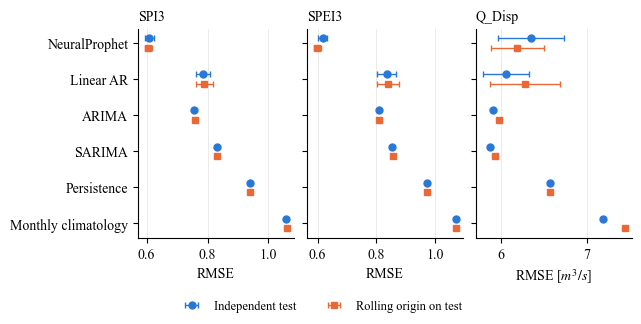

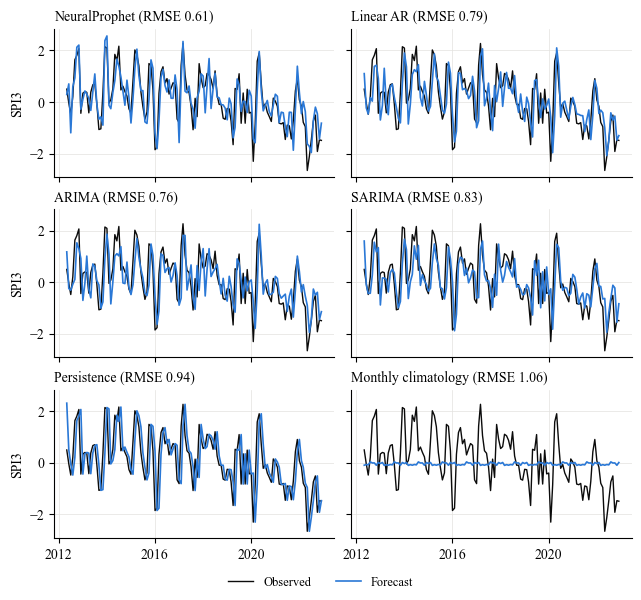

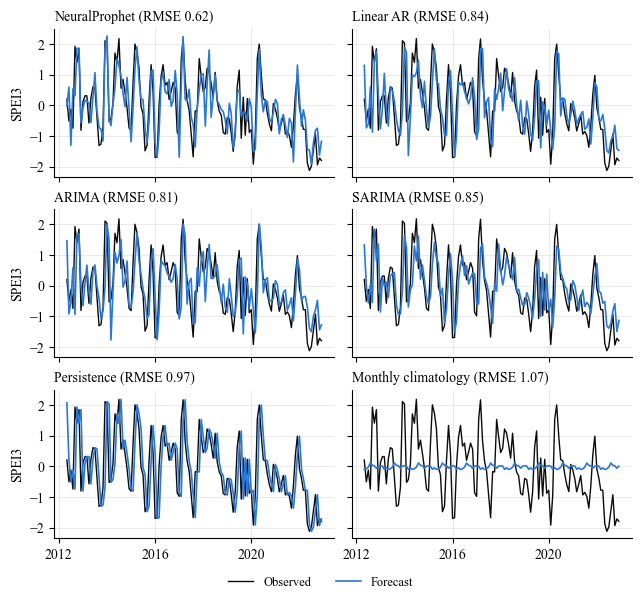

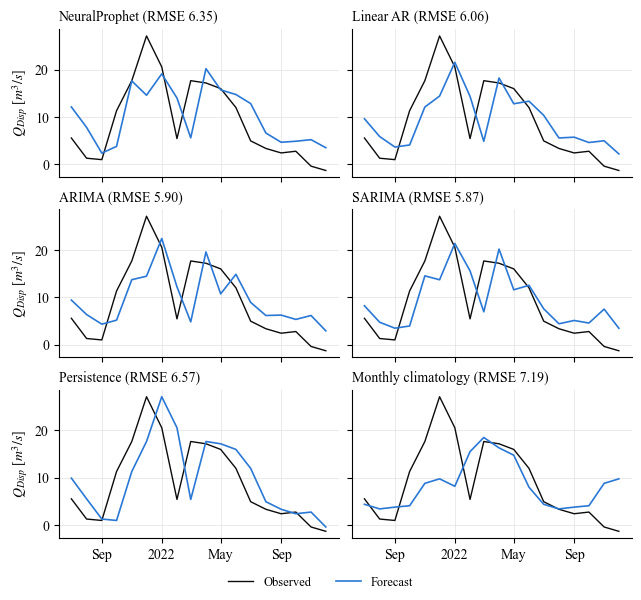

In [ ]:

for label, table in [('Test indipendente', independent_comparison), ('Rolling origin sul test', rolling_comparison)]:
    print(label)
    display(table.sort_values(['Target', 'RMSE_mean']).round(3).reset_index(drop=True))
print('Rolling origin sul test: RMSE medio per fold')
display(rolling_fold_rmse.pivot_table(index=['Target', 'Method'], columns='Fold', values='RMSE').round(3))

fig, axes = plt.subplots(1, 3, figsize=(16 * cm, 8 * cm), constrained_layout=True, sharey=True)
order = METHODS[::-1]
y = np.arange(len(order))
for ax, target in zip(axes, SPECS):
    for table, color, marker, label, shift in [(independent_comparison, '#2a78d6', 'o', 'Independent test', 0.13),
                                               (rolling_comparison, '#eb6834', 's', 'Rolling origin on test', -0.13)]:
        data = table[table.Target == target].set_index('Method').reindex(order)
        ax.errorbar(data.RMSE_mean, y + shift, xerr=data.RMSE_sd.fillna(0), fmt=marker, color=color,
                    ms=5, lw=1, capsize=2, label=label)
    ax.set_yticks(y, order)
    ax.set_title(target, loc='left')
    ax.set_xlabel(r'RMSE [$m^3/s$]' if target == 'Q_Disp' else 'RMSE')
    ax.grid(axis='x', color='#e3e2de', lw=0.5)
    ax.spines[['top', 'right']].set_visible(False)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='outside lower center', ncol=2, frameon=False)
fig.savefig(OUT / 'Comparison_RMSE.pdf', bbox_inches='tight')
fig.savefig(OUT / 'Comparison_RMSE.png', dpi=300, bbox_inches='tight')
plt.show()

test_mean = (independent_predictions.groupby(['Target', 'Method', 'ds'], as_index=False)
             .agg(Observed=('Observed', 'first'), Predicted=('Predicted', 'mean')))
for target in SPECS:
    fig, axes = plt.subplots(3, 2, figsize=(16 * cm, 15 * cm), constrained_layout=True, sharex=True, sharey=True)
    for ax, method in zip(axes.ravel(), METHODS):
        g = test_mean[(test_mean.Target == target) & (test_mean.Method == method)].sort_values('ds')
        ax.plot(g.ds, g.Observed, color=COLORS['Observed'], lw=1.0, label='Observed')
        ax.plot(g.ds, g.Predicted, color='#2a78d6', lw=1.2, label='Forecast')
        rmse = independent_comparison[(independent_comparison.Target == target)
                                      & (independent_comparison.Method == method)].RMSE_mean.iloc[0]
        ax.set_title(f'{method} (RMSE {rmse:.2f})', loc='left')
        ax.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=6))
        ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(ax.xaxis.get_major_locator()))
        ax.grid(color='#e3e2de', lw=0.5)
        ax.spines[['top', 'right']].set_visible(False)
    for ax in axes[:, 0]:
        ax.set_ylabel(UNITS[target])
    handles, labels = axes[0, 0].get_legend_handles_labels()
    fig.legend(handles, labels, loc='outside lower center', ncol=2, frameon=False)
    fig.savefig(OUT / f'{target}_independent_test_by_method.pdf', bbox_inches='tight')
    fig.savefig(OUT / f'{target}_independent_test_by_method.png', dpi=300, bbox_inches='tight')
    plt.show()


## 7. Reproducibility in a new run, SPI3 baseline, ablation, and environment files


In [ ]:

REPORT_SEEDS = [42, 123, 2026]
BASELINE_NAME = 'SPI3 with climatological P'

seed_metrics = pd.read_csv(OUT / 'Metrics_by_seed.csv')
predictions = pd.read_csv(OUT / 'Predictions_by_seed.csv', parse_dates=['ds'])
independent_predictions = pd.read_csv(OUT / 'Independent_test_predictions.csv', parse_dates=['ds'])
rolling_predictions = pd.read_csv(OUT / 'Rolling_test_predictions.csv', parse_dates=['ds'])
assert set(REPORT_SEEDS) <= set(predictions.Seed), 'REPORT_SEEDS non presenti nei risultati salvati'


def test_start_index(df):
    return len(df) - len(chronological_split(df)[2])


session_rows = []
for target, cfg in BEST.items():
    df = DATASETS[target]
    start = test_start_index(df)
    new = one_step_forecast(fit_model(target, df.iloc[:start], cfg, REPORT_SEEDS[0]), df).reindex(df.ds.iloc[start:])
    old = predictions[(predictions.Target == target) & (predictions.Partition == 'Test')
                      & (predictions.Seed == REPORT_SEEDS[0])].set_index('ds').Predicted.reindex(new.index)
    session_rows.append(dict(Target=target, Seed=REPORT_SEEDS[0], Max_abs_difference=float((new - old).abs().max())))
session_check = pd.DataFrame(session_rows)
session_check.to_csv(OUT / 'Seed_reproducibility_new_run.csv', index=False)
print('Riesecuzione rispetto ai risultati salvati'); display(session_check)


def fit_spi_transform(df_fit):
    """Gamma per mese di calendario sulla P cumulata a 3 mesi, stimata solo su df_fit."""
    p3 = df_fit.set_index('ds').Precipitation.rolling(3).sum().dropna()
    params = {}
    for month, values in p3.groupby(p3.index.month):
        positive = values[values > 0]
        shape, _, scale = gamma.fit(positive, floc=0)
        params[month] = (float((values <= 0).mean()), shape, scale)
    return params


def p3_to_spi(p3, dates, params):
    q, shape, scale = np.array([params[d.month] for d in dates]).T
    probability = q + (1 - q) * gamma.cdf(np.asarray(p3, float), shape, scale=scale)
    return norm.ppf(np.clip(probability, 1e-6, 1 - 1e-6))


def spi3_baseline(df_fit, df_predict):
    params = fit_spi_transform(df_fit)
    climatology = df_fit.groupby(df_fit.ds.dt.month).Precipitation.mean()
    d = df_predict.set_index('ds')
    p3 = d.Precipitation.shift(1) + d.Precipitation.shift(2) + d.index.month.map(climatology).values
    valid = p3.dropna()
    pred = pd.Series(p3_to_spi(valid, valid.index, params), index=valid.index)
    return pred[pred.index > df_fit.ds.max()]


df_spi = DATASETS['SPI3']
start = test_start_index(df_spi)
params = fit_spi_transform(df_spi.iloc[:start])
fidelity_rows = []
for label, part in [('Training + validation', df_spi.iloc[:start]), ('Test', df_spi)]:
    p3 = part.set_index('ds').Precipitation.rolling(3).sum().dropna()
    recomputed = pd.Series(p3_to_spi(p3, p3.index, params), index=p3.index)
    if label == 'Test':
        recomputed = recomputed[recomputed.index >= df_spi.ds.iloc[start]]
    observed = part.set_index('ds').y.reindex(recomputed.index)
    fidelity_rows.append(dict(Period=label, **compute_metrics(observed, recomputed)))
spi_fidelity = pd.DataFrame(fidelity_rows)
spi_fidelity.to_csv(OUT / 'SPI3_baseline_fidelity.csv', index=False)
print('Aderenza tra SPI3 ricalcolata con P osservata e SPI3 del dataset'); display(spi_fidelity.round(3))

baseline_independent = spi3_baseline(df_spi.iloc[:start], df_spi)
baseline_frames = [pd.DataFrame(dict(Target='SPI3', Method=BASELINE_NAME, Fold=1, Seed=REPORT_SEEDS[0],
                                     ds=baseline_independent.index,
                                     Observed=df_spi.set_index('ds').y.reindex(baseline_independent.index).values,
                                     Predicted=baseline_independent.values))]
independent_all = pd.concat([independent_predictions] + baseline_frames, ignore_index=True)

rolling_frames = []
step = 12
for fold, a in enumerate(range(start, len(df_spi), step), 1):
    b = min(a + step, len(df_spi))
    pred = spi3_baseline(df_spi.iloc[:a], df_spi.iloc[:b])
    rolling_frames.append(pd.DataFrame(dict(Target='SPI3', Method=BASELINE_NAME, Fold=fold, Seed=REPORT_SEEDS[0],
                                            ds=pred.index, Observed=df_spi.set_index('ds').y.reindex(pred.index).values,
                                            Predicted=pred.values)))
rolling_all = pd.concat([rolling_predictions] + rolling_frames, ignore_index=True)


def method_comparison(pred, label):
    pred = pred[pred.Seed.isin(REPORT_SEEDS)]
    per_seed = pd.DataFrame([dict(Target=t, Method=m, Seed=s, **compute_metrics(g.Observed, g.Predicted))
                             for (t, m, s), g in pred.groupby(['Target', 'Method', 'Seed'], sort=False)])
    table = (per_seed.groupby(['Target', 'Method'], sort=False)
             .agg(N=('N', 'first'), N_seeds=('Seed', 'nunique'), RMSE_mean=('RMSE', 'mean'), RMSE_sd=('RMSE', 'std'),
                  MAE_mean=('MAE', 'mean'), MAE_sd=('MAE', 'std'), R2_mean=('R2', 'mean'), R2_sd=('R2', 'std'),
                  r_mean=('Pearson_r', 'mean'), r_sd=('Pearson_r', 'std'),
                  Bias_mean=('Bias', 'mean'), Bias_sd=('Bias', 'std')).reset_index())
    for reference, name in [('Persistence', 'Skill_vs_persistence'), ('Monthly climatology', 'Skill_vs_climatology')]:
        ref = table[table.Method == reference].set_index('Target').RMSE_mean
        table[name] = 1 - table.RMSE_mean / table.Target.map(ref)
    table.insert(2, 'Evaluation', label)
    return table.sort_values(['Target', 'RMSE_mean']).reset_index(drop=True)


final_independent = method_comparison(independent_all, 'Independent test')
final_rolling = method_comparison(rolling_all, 'Rolling origin on test')
final_independent.to_csv(OUT / 'Final_independent_test_comparison.csv', index=False)
final_rolling.to_csv(OUT / 'Final_rolling_test_comparison.csv', index=False)


def fit_variant(target, df_fit, cfg, variant, seed):
    regressors = [] if variant == 'Without regressors' else SPECS[target]['regressors']
    hidden = [] if variant == 'Without hidden layers' else list(cfg['hidden'])
    yearly = {'Without yearly seasonality': False, 'With yearly seasonality': True}.get(variant, bool(cfg['yearly']))
    set_seed(seed)
    model = NeuralProphet(growth=cfg['growth'], yearly_seasonality=yearly, weekly_seasonality=False,
                          daily_seasonality=False, n_lags=int(cfg['n_lags']), n_forecasts=1,
                          ar_layers=hidden, lagged_reg_layers=hidden,
                          learning_rate=float(cfg['learning_rate']), epochs=EPOCHS[target])
    if regressors:
        model.add_lagged_regressor(names=regressors, n_lags=int(cfg['n_lags']))
    columns = ['ds', 'y'] + regressors
    model.fit(df_fit[columns], freq='MS', progress=None)
    return model, columns


ablation_rows = []
for target, cfg in BEST.items():
    df = DATASETS[target]
    start = test_start_index(df)
    test = df.iloc[start:]
    full = independent_predictions[(independent_predictions.Target == target)
                                   & (independent_predictions.Method == 'NeuralProphet')
                                   & independent_predictions.Seed.isin(REPORT_SEEDS)]
    full_parameters = int(seed_metrics[seed_metrics.Target == target].Trainable_parameters.iloc[0])
    for seed, g in full.groupby('Seed'):
        ablation_rows.append(dict(Target=target, Variant='Full model', Seed=seed, Parameters=full_parameters,
                                  **compute_metrics(g.Observed, g.Predicted)))
    seasonal_variant = 'Without yearly seasonality' if cfg['yearly'] else 'With yearly seasonality'
    for variant in ['Without regressors', 'Without hidden layers', seasonal_variant]:
        for seed in REPORT_SEEDS:
            model, columns = fit_variant(target, df.iloc[:start], cfg, variant, seed)
            pred = one_step_forecast(model, df[columns]).reindex(test.ds)
            ablation_rows.append(dict(Target=target, Variant=variant, Seed=seed, Parameters=count_parameters(model),
                                      **compute_metrics(test.y, pred)))
        print(f'Ablation | {target} | {variant} completato')
    linear_cfg = BEST_BY_METHOD[target]['Linear AR']
    linear_parameters = count_parameters(fit_linear_ar(target, df.iloc[:start], linear_cfg, REPORT_SEEDS[0]))
    linear = independent_predictions[(independent_predictions.Target == target)
                                     & (independent_predictions.Method == 'Linear AR')
                                     & independent_predictions.Seed.isin(REPORT_SEEDS)]
    for seed, g in linear.groupby('Seed'):
        ablation_rows.append(dict(Target=target, Variant='Linear AR', Seed=seed, Parameters=linear_parameters,
                                  **compute_metrics(g.Observed, g.Predicted)))

ablation_by_seed = pd.DataFrame(ablation_rows)
ablation_table = (ablation_by_seed.groupby(['Target', 'Variant'], sort=False)
                  .agg(Parameters=('Parameters', 'first'), N_seeds=('Seed', 'nunique'),
                       RMSE_mean=('RMSE', 'mean'), RMSE_sd=('RMSE', 'std'), MAE_mean=('MAE', 'mean'), MAE_sd=('MAE', 'std'),
                       R2_mean=('R2', 'mean'), R2_sd=('R2', 'std'), r_mean=('Pearson_r', 'mean'), r_sd=('Pearson_r', 'std'),
                       Bias_mean=('Bias', 'mean'), Bias_sd=('Bias', 'std')).reset_index())
full_rmse = ablation_table[ablation_table.Variant == 'Full model'].set_index('Target').RMSE_mean
ablation_table['Delta_RMSE_vs_full'] = ablation_table.RMSE_mean - ablation_table.Target.map(full_rmse)
ablation_by_seed.to_csv(OUT / 'Ablation_by_seed.csv', index=False)
ablation_table.to_csv(OUT / 'Ablation_summary.csv', index=False)

requirements = subprocess.run([sys.executable, '-m', 'pip', 'freeze'], capture_output=True, text=True, check=True).stdout
(OUT / 'requirements_frozen.txt').write_text(requirements, encoding='utf-8')
manifest = dict(python=platform.python_version(), platform=platform.platform(),
                neuralprophet=neuralprophet.__version__, torch=torch.__version__,
                train_ratio=TRAIN_RATIO, val_ratio=VAL_RATIO, tuning_seed=TUNING_SEED, report_seeds=REPORT_SEEDS,
                epochs=EPOCHS, regressors={t: s['regressors'] for t, s in SPECS.items()},
                selected_configurations=BEST_BY_METHOD)
(OUT / 'Run_manifest.json').write_text(json.dumps(manifest, indent=2), encoding='utf-8')
search_table.to_csv(OUT / 'Hyperparameter_search_with_eligibility.csv', index=False)
print('Calcoli di chiusura completati.')


Riesecuzione rispetto ai risultati salvati


,Target,Seed,Max_abs_difference
0,SPI3,42,4.440892e-16
1,SPEI3,42,4.440892e-16
2,Q_Disp,42,1.776357e-15


Aderenza tra SPI3 ricalcolata con P osservata e SPI3 del dataset


,Period,N,RMSE,MAE,R2,Pearson_r,Bias
0,Training + validation,722,0.159,0.065,0.973,0.989,0.044
1,Test,128,0.281,0.109,0.927,0.971,0.095


Ablation | SPI3 | Without regressors completato
Ablation | SPI3 | Without hidden layers completato
Ablation | SPI3 | Without yearly seasonality completato
Ablation | SPEI3 | Without regressors completato
Ablation | SPEI3 | Without hidden layers completato
Ablation | SPEI3 | Without yearly seasonality completato
Ablation | Q_Disp | Without regressors completato
Ablation | Q_Disp | Without hidden layers completato
Ablation | Q_Disp | With yearly seasonality completato
Calcoli di chiusura completati.


## 8. Tables of results for the selected seeds

In [ ]:
ORDER_TARGETS = list(SPECS)
ORDER_PARTITIONS = ['Training', 'Validation', 'Test']
METRICS = ['RMSE', 'MAE', 'R2', 'Pearson_r', 'Bias']

selected_seeds = seed_metrics[seed_metrics.Seed.isin(REPORT_SEEDS)]
seed_rows = []
for target in ORDER_TARGETS:
    for partition in ORDER_PARTITIONS:
        g = selected_seeds[(selected_seeds.Target == target) & (selected_seeds.Partition == partition)]
        base = dict(Target=target, Partition=partition, Parameters=int(g.Trainable_parameters.iloc[0]), N=int(g.N.iloc[0]))
        seed_rows += [base | dict(Seed=str(r.Seed), **{m: getattr(r, m) for m in METRICS}) for r in g.itertuples()]
        seed_rows.append(base | dict(Seed='Mean', **{m: g[m].mean() for m in METRICS}))
        seed_rows.append(base | dict(Seed='SD', **{m: g[m].std() for m in METRICS}))
results_by_seed = pd.DataFrame(seed_rows)[['Target', 'Partition', 'Seed', 'Parameters', 'N'] + METRICS]
results_by_seed.to_csv(OUT / 'Results_table_report_seeds.csv', index=False)

compact = selected_seeds.groupby(['Target', 'Partition'], sort=False).agg(
    N=('N', 'first'), **{f'{m}_mean': (m, 'mean') for m in METRICS}, **{f'{m}_sd': (m, 'std') for m in METRICS}).reset_index()
paper_style = compact[['Target', 'Partition', 'N']].copy()
for m in METRICS:
    paper_style[m] = compact[f'{m}_mean'].map('{:.3f}'.format) + ' ± ' + compact[f'{m}_sd'].map('{:.3f}'.format)
paper_style.to_csv(OUT / 'Results_table_mean_sd_report_seeds.csv', index=False)

print(f'NeuralProphet con i seed {REPORT_SEEDS}: ogni seed, media e SD'); display(results_by_seed.round(3))
print('NeuralProphet: media ± SD'); display(paper_style)
print('Test indipendente: tutti i metodi'); display(final_independent.round(3))
print('Rolling origin sul test: tutti i metodi'); display(final_rolling.round(3))
print('Ablation sul test indipendente'); display(ablation_table.round(3))


NeuralProphet con i seed [42, 123, 2026]: ogni seed, media e SD


,Target,Partition,Seed,Parameters,N,RMSE,MAE,R2,Pearson_r,Bias
0,SPI3,Training,42,189,593,0.513,0.407,0.697,0.835,-0.016
1,SPI3,Training,123,189,593,0.494,0.387,0.719,0.848,-0.014
2,SPI3,Training,2026,189,593,0.527,0.415,0.681,0.825,-0.009
3,SPI3,Training,Mean,189,593,0.511,0.403,0.699,0.836,-0.013
4,SPI3,Training,SD,189,593,0.016,0.015,0.019,0.011,0.004
5,SPI3,Validation,42,189,128,0.615,0.492,0.697,0.838,0.063
6,SPI3,Validation,123,189,128,0.626,0.496,0.686,0.831,-0.038
7,SPI3,Validation,2026,189,128,0.638,0.507,0.674,0.823,-0.061
8,SPI3,Validation,Mean,189,128,0.627,0.498,0.686,0.831,-0.012
9,SPI3,Validation,SD,189,128,0.012,0.008,0.012,0.007,0.066


NeuralProphet: media ± SD


,Target,Partition,N,RMSE,MAE,R2,Pearson_r,Bias
0,SPI3,Training,593,0.511 ± 0.016,0.403 ± 0.015,0.699 ± 0.019,0.836 ± 0.011,-0.013 ± 0.004
1,SPI3,Validation,128,0.627 ± 0.012,0.498 ± 0.008,0.686 ± 0.012,0.831 ± 0.007,-0.012 ± 0.066
2,SPI3,Test,128,0.614 ± 0.013,0.499 ± 0.007,0.649 ± 0.015,0.813 ± 0.009,0.006 ± 0.029
3,SPEI3,Training,593,0.521 ± 0.013,0.412 ± 0.013,0.697 ± 0.015,0.835 ± 0.009,-0.017 ± 0.002
4,SPEI3,Validation,128,0.622 ± 0.013,0.516 ± 0.010,0.712 ± 0.012,0.845 ± 0.009,0.020 ± 0.065
5,SPEI3,Test,128,0.617 ± 0.016,0.503 ± 0.012,0.656 ± 0.018,0.814 ± 0.008,0.022 ± 0.011
6,Q_Disp,Training,81,6.613 ± 0.190,4.174 ± 0.270,0.558 ± 0.025,0.749 ± 0.016,-0.502 ± 0.195
7,Q_Disp,Validation,18,3.912 ± 0.657,3.076 ± 0.679,0.563 ± 0.150,0.824 ± 0.057,1.673 ± 0.509
8,Q_Disp,Test,18,6.370 ± 0.371,5.141 ± 0.467,0.397 ± 0.071,0.649 ± 0.047,1.048 ± 0.164


Test indipendente: tutti i metodi


,Target,Method,Evaluation,N,N_seeds,RMSE_mean,RMSE_sd,MAE_mean,MAE_sd,R2_mean,R2_sd,r_mean,r_sd,Bias_mean,Bias_sd,Skill_vs_persistence,Skill_vs_climatology
0,Q_Disp,SARIMA,Independent test,18,1,5.868,NaN,4.604,NaN,0.490,NaN,0.701,NaN,0.259,NaN,0.107,0.183
1,Q_Disp,ARIMA,Independent test,18,1,5.900,NaN,5.048,NaN,0.484,NaN,0.700,NaN,0.503,NaN,0.102,0.179
2,Q_Disp,Linear AR,Independent test,18,3,6.137,0.351,4.908,0.379,0.441,0.065,0.675,0.032,0.331,0.533,0.066,0.146
3,Q_Disp,NeuralProphet,Independent test,18,3,6.370,0.371,5.141,0.467,0.397,0.071,0.649,0.047,1.048,0.164,0.030,0.114
4,Q_Disp,Persistence,Independent test,18,1,6.569,NaN,4.924,NaN,0.361,NaN,0.668,NaN,0.623,NaN,0.000,0.086
5,Q_Disp,Monthly climatology,Independent test,18,1,7.186,NaN,5.140,NaN,0.235,NaN,0.502,NaN,-0.807,NaN,-0.094,0.000
6,SPEI3,NeuralProphet,Independent test,128,3,0.617,0.016,0.503,0.012,0.656,0.018,0.814,0.008,0.022,0.011,0.365,0.423
7,SPEI3,ARIMA,Independent test,128,1,0.809,NaN,0.611,NaN,0.409,NaN,0.660,NaN,0.014,NaN,0.167,0.243
8,SPEI3,Linear AR,Independent test,128,3,0.845,0.041,0.650,0.038,0.354,0.064,0.631,0.031,0.018,0.023,0.130,0.209
9,SPEI3,SARIMA,Independent test,128,1,0.853,NaN,0.663,NaN,0.343,NaN,0.598,NaN,0.021,NaN,0.122,0.202


Rolling origin sul test: tutti i metodi


,Target,Method,Evaluation,N,N_seeds,RMSE_mean,RMSE_sd,MAE_mean,MAE_sd,R2_mean,R2_sd,r_mean,r_sd,Bias_mean,Bias_sd,Skill_vs_persistence,Skill_vs_climatology
0,Q_Disp,SARIMA,Rolling origin on test,18,1,5.929,NaN,4.670,NaN,0.479,NaN,0.693,NaN,0.315,NaN,0.097,0.203
1,Q_Disp,ARIMA,Rolling origin on test,18,1,5.971,NaN,5.149,NaN,0.472,NaN,0.692,NaN,0.611,NaN,0.091,0.198
2,Q_Disp,NeuralProphet,Rolling origin on test,18,3,6.189,0.305,4.896,0.315,0.431,0.057,0.672,0.039,0.995,0.164,0.058,0.168
3,Q_Disp,Linear AR,Rolling origin on test,18,3,6.277,0.406,5.005,0.390,0.414,0.077,0.656,0.039,0.558,0.747,0.044,0.157
4,Q_Disp,Persistence,Rolling origin on test,18,1,6.569,NaN,4.924,NaN,0.361,NaN,0.668,NaN,0.623,NaN,0.000,0.117
5,Q_Disp,Monthly climatology,Rolling origin on test,18,1,7.442,NaN,5.326,NaN,0.179,NaN,0.453,NaN,-0.624,NaN,-0.133,0.000
6,SPEI3,NeuralProphet,Rolling origin on test,128,3,0.600,0.012,0.486,0.010,0.676,0.013,0.825,0.009,0.034,0.014,0.383,0.439
7,SPEI3,ARIMA,Rolling origin on test,128,1,0.807,NaN,0.614,NaN,0.412,NaN,0.657,NaN,0.023,NaN,0.169,0.245
8,SPEI3,Linear AR,Rolling origin on test,128,3,0.839,0.038,0.650,0.035,0.363,0.059,0.632,0.028,0.023,0.018,0.136,0.215
9,SPEI3,SARIMA,Rolling origin on test,128,1,0.855,NaN,0.667,NaN,0.340,NaN,0.593,NaN,0.028,NaN,0.120,0.200


Ablation sul test indipendente


,Target,Variant,Parameters,N_seeds,RMSE_mean,RMSE_sd,MAE_mean,MAE_sd,R2_mean,R2_sd,r_mean,r_sd,Bias_mean,Bias_sd,Delta_RMSE_vs_full
0,SPI3,Full model,189,3,0.614,0.013,0.499,0.007,0.649,0.015,0.813,0.009,0.006,0.029,0.000
1,SPI3,Without regressors,53,3,0.837,0.007,0.631,0.011,0.349,0.011,0.618,0.009,-0.045,0.004,0.223
2,SPI3,Without hidden layers,31,3,0.655,0.033,0.534,0.028,0.600,0.040,0.788,0.027,0.021,0.026,0.041
3,SPI3,Without yearly seasonality,177,3,0.624,0.012,0.509,0.016,0.638,0.014,0.808,0.004,-0.026,0.039,0.010
4,SPI3,Linear AR,13,3,0.795,0.029,0.623,0.020,0.411,0.043,0.669,0.021,-0.025,0.065,0.181
5,SPEI3,Full model,189,3,0.617,0.016,0.503,0.012,0.656,0.018,0.814,0.008,0.022,0.011,0.000
6,SPEI3,Without regressors,53,3,0.868,0.004,0.650,0.006,0.321,0.007,0.598,0.007,0.002,0.011,0.250
7,SPEI3,Without hidden layers,31,3,0.635,0.019,0.519,0.019,0.636,0.022,0.805,0.015,0.039,0.010,0.017
8,SPEI3,Without yearly seasonality,177,3,0.621,0.007,0.508,0.007,0.652,0.007,0.815,0.006,-0.018,0.052,0.004
9,SPEI3,Linear AR,13,3,0.845,0.041,0.650,0.038,0.354,0.064,0.631,0.031,0.018,0.023,0.228


## 9. Figure

Intervalli | SPI3 completato
Intervalli | SPEI3 completato
Intervalli | Q_Disp completato
Copertura degli intervalli nel test


,Target,Nominal_coverage,Calibration_months,Half_width,Test_months,Empirical_coverage,Months_outside
0,SPI3,0.9,120,1.036,128,0.883,15
1,SPEI3,0.9,120,0.995,128,0.883,15
2,Q_Disp,0.9,36,6.751,18,0.722,5


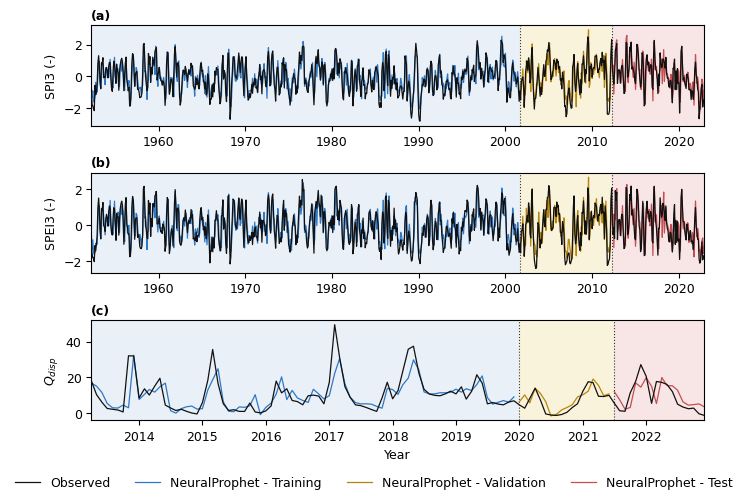

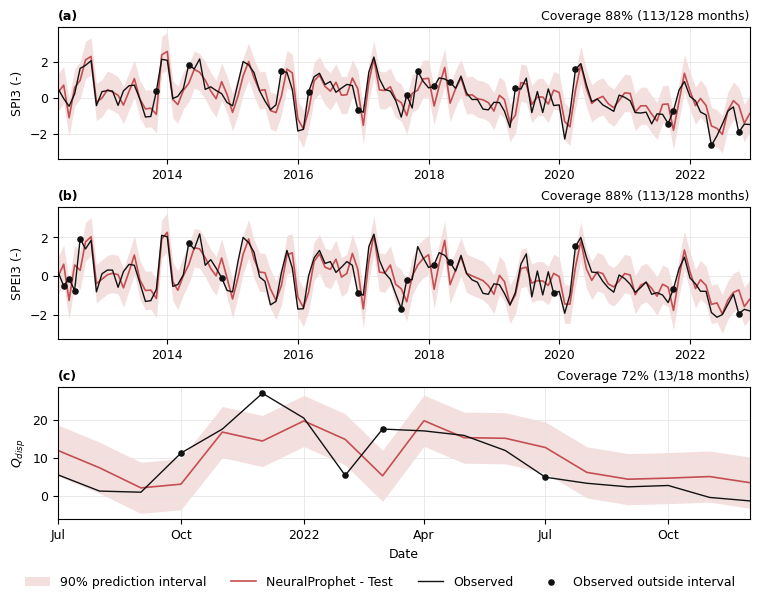

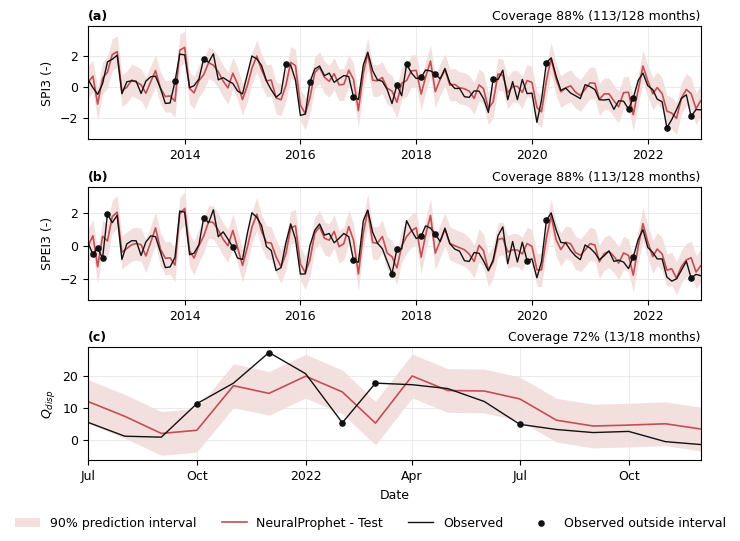

In [ ]:

ALPHA = 0.10
FIGURE_COLORS = {'Observed': '#111111', 'Training': '#2F78C4', 'Validation': '#B8860B', 'Test': '#C44E52'}
SHADES = {'Training': '#E9F0F7', 'Validation': '#FAF3DC', 'Test': '#F8E6E6'}
YLABELS = {'SPI3': 'SPI3 (-)', 'SPEI3': 'SPEI3 (-)', 'Q_Disp':  r'$Q_{disp}$'}
PANELS = dict(zip(SPECS, ['(a)', '(b)', '(c)']))
SCATTER_NAMES = {'SPI3': 'SPI3', 'SPEI3': 'SPEI3', 'Q_Disp': r'$Q_{disp}$'}
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 9, 'axes.labelsize': 9, 'axes.titlesize': 9,
                     'xtick.labelsize': 9, 'ytick.labelsize': 9, 'legend.fontsize': 9, 'mathtext.fontset': 'dejavusans'})
cm = 1 / 2.54


def add_panel_label(ax, target):
    ax.text(0.0, 1.03, PANELS[target], transform=ax.transAxes, fontweight='bold', va='bottom')


def save_figure(fig, name):
    fig.savefig(OUT / f'{name}.pdf', bbox_inches='tight')
    fig.savefig(OUT / f'{name}.png', dpi=300, bbox_inches='tight')
    plt.show()


calibration_rows, interval_rows = [], []
report_predictions = predictions[predictions.Seed.isin(REPORT_SEEDS)]
mean_forecasts = (report_predictions.groupby(['Target', 'Partition', 'ds'], as_index=False)
                  .agg(Observed=('Observed', 'first'), Forecast=('Predicted', 'mean')))
test_intervals = []
for target, cfg in BEST.items():
    df = DATASETS[target]
    dev = df.iloc[:test_start_index(df)].reset_index(drop=True)
    n_folds, horizon = DEV_FOLDS[target]
    folds = [(len(dev) - (n_folds - i) * horizon, len(dev) - (n_folds - i - 1) * horizon) for i in range(n_folds)]
    calibration = evaluate_folds('NeuralProphet', target, cfg, dev, folds, REPORT_SEEDS)
    calibration = calibration.groupby('ds', as_index=False).agg(Observed=('Observed', 'first'), Forecast=('Predicted', 'mean'))
    errors = np.sort((calibration.Observed - calibration.Forecast).abs().values)
    n = len(errors)
    rank = int(np.ceil((n + 1) * (1 - ALPHA)))
    half_width = float(errors[min(rank, n) - 1])
    g = mean_forecasts[(mean_forecasts.Target == target) & (mean_forecasts.Partition == 'Test')].sort_values('ds').copy()
    g['Lower'], g['Upper'] = g.Forecast - half_width, g.Forecast + half_width
    g['Inside'] = g.Observed.between(g.Lower, g.Upper)
    test_intervals.append(g)
    interval_rows.append(dict(Target=target, Nominal_coverage=1 - ALPHA, Calibration_months=n, Half_width=half_width,
                              Test_months=len(g), Empirical_coverage=float(g.Inside.mean()),
                              Months_outside=int((~g.Inside).sum())))
    print(f'Intervalli | {target} completato')
test_intervals = pd.concat(test_intervals, ignore_index=True)
interval_summary = pd.DataFrame(interval_rows)
test_intervals.to_csv(OUT / 'Test_prediction_intervals.csv', index=False)
interval_summary.to_csv(OUT / 'Prediction_interval_summary.csv', index=False)
print('Copertura degli intervalli nel test'); display(interval_summary.round(3))

fig, axes = plt.subplots(3, 1, figsize=(17 * cm, 12.5 * cm), constrained_layout=True)
for ax, target in zip(axes, SPECS):
    data = mean_forecasts[mean_forecasts.Target == target]
    observed = data.sort_values('ds').drop_duplicates('ds')
    starts = [data[data.Partition == p].ds.min() for p in ORDER_PARTITIONS] + [observed.ds.max()]
    for i, partition in enumerate(ORDER_PARTITIONS):
        g = data[data.Partition == partition].sort_values('ds')
        ax.axvspan(starts[i], starts[i + 1], color=SHADES[partition], lw=0, zorder=0)
        ax.plot(g.ds, g.Forecast, color=FIGURE_COLORS[partition], lw=0.9, zorder=2, label=f'NeuralProphet - {partition}')
        if partition != 'Training':
            ax.axvline(g.ds.min(), color='#333333', ls=':', lw=0.8, zorder=1)
    ax.plot(observed.ds, observed.Observed, color=FIGURE_COLORS['Observed'], lw=0.9, zorder=3, label='Observed')
    ax.set_xlim(observed.ds.min(), observed.ds.max())
    ax.set_ylabel(YLABELS[target])
    add_panel_label(ax, target)
axes[-1].set_xlabel('Year')
handles, labels = axes[0].get_legend_handles_labels() 
order = [3, 0, 1, 2] 
fig.legend([handles[i] for i in order], [labels[i] for i in order], loc='outside lower center', ncol=4, frameon=False)
save_figure(fig, 'Figure_9') 

fig, axes = plt.subplots(3, 1, figsize=(19 * cm, 15 * cm), constrained_layout=True)
for ax, target in zip(axes, SPECS):
    g = test_intervals[test_intervals.Target == target]
    row = interval_summary[interval_summary.Target == target].iloc[0]
    ax.fill_between(g.ds, g.Lower, g.Upper, color=FIGURE_COLORS['Test'], alpha=0.18, lw=0, label='90% prediction interval')
    ax.plot(g.ds, g.Forecast, color=FIGURE_COLORS['Test'], lw=1.2, label='NeuralProphet - Test')
    ax.plot(g.ds, g.Observed, color=FIGURE_COLORS['Observed'], lw=1.0, label='Observed')
    outside = g[~g.Inside]
    ax.scatter(outside.ds, outside.Observed, s=14, color=FIGURE_COLORS['Observed'], zorder=4, label='Observed outside interval')
    ax.set_xlim(g.ds.min(), g.ds.max())
    ax.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=9))
    ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(ax.xaxis.get_major_locator()))
    ax.set_ylabel(YLABELS[target])
    ax.grid(color='#E3E2DE', lw=0.5)
    ax.text(1.0, 1.03, f'Coverage {row.Empirical_coverage:.0%} ({row.Test_months - row.Months_outside}/{row.Test_months} months)',
            transform=ax.transAxes, ha='right', va='bottom')
    add_panel_label(ax, target)
axes[-1].set_xlabel('Date')
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='outside lower center', ncol=4, frameon=False)
save_figure(fig, 'Figure_test_9b')


fig, axes = plt.subplots(3, 1, figsize=(17 * cm, 13.5 * cm), constrained_layout=True)
for ax, target in zip(axes, SPECS):
    g = test_intervals[test_intervals.Target == target]
    row = interval_summary[interval_summary.Target == target].iloc[0]
    ax.fill_between(g.ds, g.Lower, g.Upper, color=FIGURE_COLORS['Test'], alpha=0.18, lw=0, label='90% prediction interval')
    ax.plot(g.ds, g.Forecast, color=FIGURE_COLORS['Test'], lw=1.2, label='NeuralProphet - Test')
    ax.plot(g.ds, g.Observed, color=FIGURE_COLORS['Observed'], lw=1.0, label='Observed')
    outside = g[~g.Inside]
    ax.scatter(outside.ds, outside.Observed, s=14, color=FIGURE_COLORS['Observed'], zorder=4, label='Observed outside interval')
    ax.set_xlim(g.ds.min(), g.ds.max())
    ax.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=9))
    ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(ax.xaxis.get_major_locator()))
    ax.set_ylabel(YLABELS[target])
    ax.grid(color='#E3E2DE', lw=0.5)
    ax.text(1.0, 1.03, f'Coverage {row.Empirical_coverage:.0%} ({row.Test_months - row.Months_outside}/{row.Test_months} months)',
            transform=ax.transAxes, ha='right', va='bottom')
    add_panel_label(ax, target)
axes[-1].set_xlabel('Date')
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='outside lower center', ncol=4, frameon=False)
save_figure(fig, 'Figure_9c')



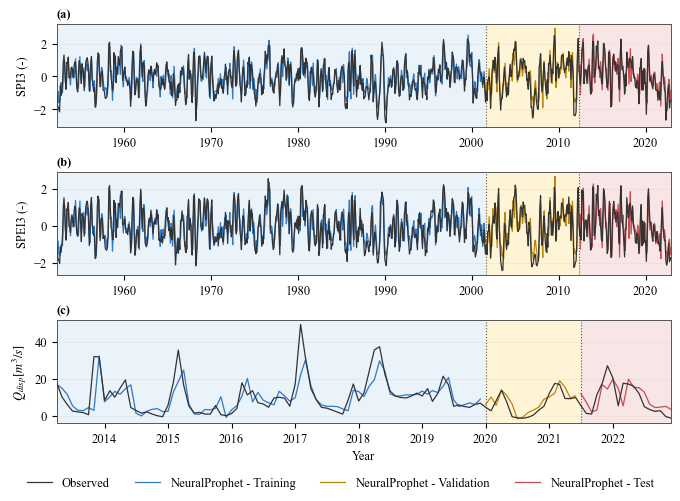

In [ ]:
ALPHA = 0.10
FIGURE_COLORS = {'Observed': '#111111', 'Training': '#2F78C4', 'Validation': '#B8860B', 'Test': '#C44E52'}
SHADES = {'Training': '#E9F0F7', 'Validation': '#FAF3DC', 'Test': '#F8E6E6'}
YLABELS = {'SPI3': 'SPI3 (-)', 'SPEI3': 'SPEI3 (-)', 'Q_Disp':  r'$Q_{disp} [m^3/s]$'}
PANELS = dict(zip(SPECS, ['(a)', '(b)', '(c)']))
SCATTER_NAMES = {'SPI3': 'SPI3', 'SPEI3': 'SPEI3', 'Q_Disp': r'$Q_{disp} [m^3/s]$'}

plt.rcParams.update({
    'font.family': 'Times New Roman',
    'font.size': 9,
    'axes.labelsize': 9,
    'axes.titlesize': 9,
    'xtick.labelsize': 9,
    'ytick.labelsize': 9,
    'legend.fontsize': 9,
    'mathtext.fontset': 'stix',
    'pdf.fonttype': 42,
    'ps.fonttype': 42,
})

cm = 1 / 2.54

FIGURE_COLORS = {
    'Training': '#2F78C4',
    'Validation': '#B8860B',
    'Test': '#C44E52',
    'Observed': '#333333'
}


SHADES = {
    'Training': '#EAF2FA',
    'Validation': '#FFF5D6',
    'Test': '#F8E6E6'
}

ORDER_PARTITIONS = ['Training', 'Validation', 'Test']

fig, axes = plt.subplots(
    3, 1,
    figsize=(17 * cm, 12.5 * cm),
    constrained_layout=True
)

for ax, target in zip(axes, SPECS):

    data = mean_forecasts[
        mean_forecasts.Target == target
    ]

    observed = (
        data.sort_values('ds')
        .drop_duplicates('ds')
    )

    starts = [
        data[data.Partition == p].ds.min()
        for p in ORDER_PARTITIONS
    ] + [observed.ds.max()]

    for i, partition in enumerate(ORDER_PARTITIONS):

        g = (
            data[data.Partition == partition]
            .sort_values('ds')
        )

        ax.axvspan(
            starts[i],
            starts[i + 1],
            color=SHADES[partition],
            lw=0,
            zorder=0
        )

        ax.plot(
            g.ds,
            g.Forecast,
            color=FIGURE_COLORS[partition],
            lw=0.9,
            zorder=2,
            label=f'NeuralProphet - {partition}'
        )

        if partition != 'Training':
            ax.axvline(
                g.ds.min(),
                color='#555555',
                ls=':',
                lw=0.8,
                zorder=1
            )

    ax.plot(
        observed.ds,
        observed.Observed,
        color=FIGURE_COLORS['Observed'],
        lw=0.9,
        zorder=3,
        label='Observed'
    )

    ax.set_xlim(
        observed.ds.min(),
        observed.ds.max()
    )

    ax.set_ylabel(
        YLABELS[target],
        fontsize=9
    )

    add_panel_label(ax, target)

    ax.grid(
        axis='y',
        color='#D9D9D9',
        lw=0.4,
        alpha=0.7
    )

    ax.set_axisbelow(True)

    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_color('#555555')
        spine.set_linewidth(0.7)

    ax.tick_params(
        axis='both',
        labelsize=9
    )

axes[-1].set_xlabel(
    'Year',
    fontsize=9
)

handles, labels = axes[0].get_legend_handles_labels()

order = [3, 0, 1, 2]

fig.legend(
    [handles[i] for i in order],
    [labels[i] for i in order],
    loc='outside lower center',
    ncol=4,
    frameon=False,
    fontsize=9
)

save_figure(fig, 'Figure_9')

plt.show()



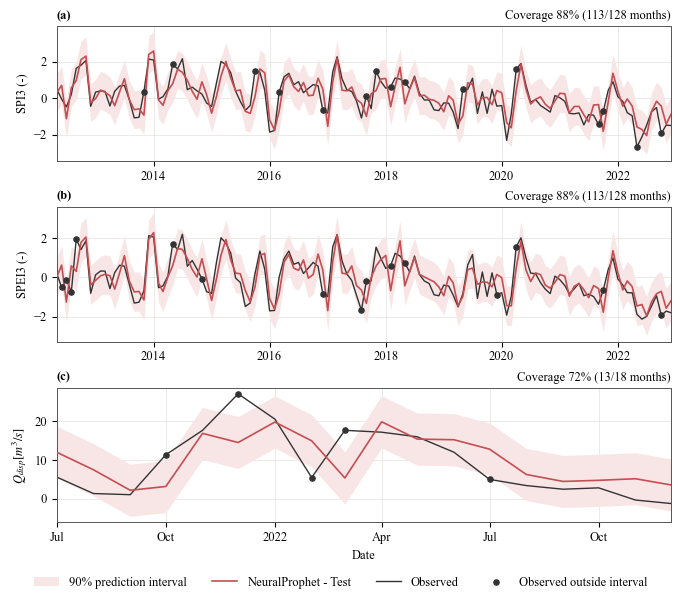

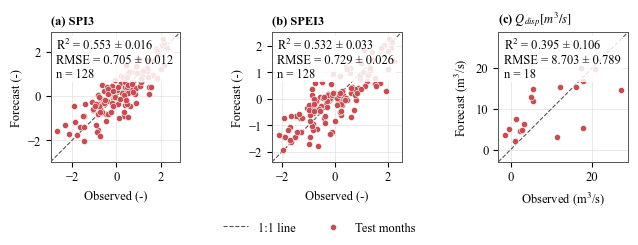

In [ ]:
plt.rcParams.update({
    'font.family': 'Times New Roman',
    'font.size': 9,
    'axes.labelsize': 9,
    'axes.titlesize': 9,
    'xtick.labelsize': 9,
    'ytick.labelsize': 9,
    'legend.fontsize': 9,
    'mathtext.fontset': 'stix',
    'pdf.fonttype': 42,
    'ps.fonttype': 42,
})

cm = 1 / 2.54

FIGURE_COLORS = {
    'Training': '#2F78C4',
    'Validation': '#B8860B',
    'Test': '#C44E52',
    'Observed': '#333333'
}

TEST_SHADE = '#F8E6E6'
GRID_COLOR = '#E3E2DE'

fig, axes = plt.subplots(
    3, 1,
    figsize=(17 * cm, 15 * cm),
    constrained_layout=True
)

for ax, target in zip(axes, SPECS):

    g = (
        test_intervals[
            test_intervals.Target == target
        ]
        .sort_values('ds')
    )

    row = interval_summary[
        interval_summary.Target == target
    ].iloc[0]

    
    ax.fill_between(
        g.ds,
        g.Lower,
        g.Upper,
        color=TEST_SHADE,
        alpha=1.0,
        lw=0,
        label='90% prediction interval',
        zorder=1
    )

    ax.plot(
        g.ds,
        g.Forecast,
        color=FIGURE_COLORS['Test'],
        lw=1.2,
        label='NeuralProphet - Test',
        zorder=3
    )

    ax.plot(
        g.ds,
        g.Observed,
        color=FIGURE_COLORS['Observed'],
        lw=1.0,
        label='Observed',
        zorder=2
    )

    outside = g[~g.Inside]

    ax.scatter(
        outside.ds,
        outside.Observed,
        s=14,
        color=FIGURE_COLORS['Observed'],
        zorder=4,
        label='Observed outside interval'
    )

    ax.set_xlim(g.ds.min(), g.ds.max())

    locator = mdates.AutoDateLocator(maxticks=9)
    ax.xaxis.set_major_locator(locator)
    ax.xaxis.set_major_formatter(
        mdates.ConciseDateFormatter(locator)
    )

    ax.set_ylabel(YLABELS[target], fontsize=9)

    ax.grid(
        True,
        axis='both',
        color=GRID_COLOR,
        linestyle='-',
        linewidth=0.5
    )

    ax.set_axisbelow(True)

    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_color('#555555')
        spine.set_linewidth(0.7)

    ax.tick_params(
        axis='both',
        labelsize=9,
        direction='out'
    )

    ax.text(
        1.0,
        1.03,
        (
            f'Coverage {row.Empirical_coverage:.0%} '
            f'({row.Test_months - row.Months_outside}/'
            f'{row.Test_months} months)'
        ),
        transform=ax.transAxes,
        ha='right',
        va='bottom',
        fontsize=9
    )

    add_panel_label(ax, target)

axes[-1].set_xlabel('Date', fontsize=9)

handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc='outside lower center',
    ncol=4,
    frameon=False,
    fontsize=9
)

save_figure(fig, 'Figure_9b')

plt.show()

plt.rcParams.update({
    'font.family': 'Times New Roman',
    'font.size': 9,
    'axes.labelsize': 9,
    'axes.titlesize': 9,
    'xtick.labelsize': 9,
    'ytick.labelsize': 9,
    'legend.fontsize': 9,
    'mathtext.fontset': 'stix',
    'pdf.fonttype': 42,
    'ps.fonttype': 42,
})

cm = 1 / 2.54

TEST_COLOR = '#C44E52'
GRID_COLOR = '#E3E2DE'

SEED_METRICS = {
    'SPI3': {
        'R2': (0.553, 0.016),
        'RMSE': (0.705, 0.012)
    },
    'SPEI3': {
        'R2': (0.532, 0.033),
        'RMSE': (0.729, 0.026)
    },
    'Q_Disp': {
        'R2': (0.395, 0.106),
        'RMSE': (8.703, 0.789)
    }
}

fig, axes = plt.subplots(
    1, 3,
    figsize=(17 * cm, 6 * cm),
    constrained_layout=True
)

for ax, target in zip(axes, SPECS):

    g = test_intervals[
        test_intervals.Target == target
    ]

    low = min(
        g.Observed.min(),
        g.Forecast.min()
    )

    high = max(
        g.Observed.max(),
        g.Forecast.max()
    )

    pad = 0.06 * (high - low)
    limits = (low - pad, high + pad)

    ax.plot(
        limits,
        limits,
        color='#555555',
        ls='--',
        lw=0.8,
        label='1:1 line',
        zorder=1
    )

    ax.scatter(
        g.Observed,
        g.Forecast,
        s=20,
        color=TEST_COLOR,
        edgecolor='white',
        linewidth=0.4,
        label='Test months',
        zorder=3
    )

    result = compute_metrics(
        g.Observed,
        g.Forecast
    )

    metrics = SEED_METRICS[target]

    ax.text(
        0.04,
        0.96,
        (
            f"R$^2$ = {metrics['R2'][0]:.3f} ± {metrics['R2'][1]:.3f}\n"
            f"RMSE = {metrics['RMSE'][0]:.3f} ± {metrics['RMSE'][1]:.3f}\n"
            f"n = {len(g)}"
        ),
        transform=ax.transAxes,
        va='top',
        fontsize=9,
        bbox=dict(
            facecolor='white',
            edgecolor='none',
            alpha=0.85,
            pad=1.5
        ),
        zorder=4
    )

    ax.set_xlim(limits)
    ax.set_ylim(limits)

    ax.set_aspect(
        'equal',
        adjustable='box'
    )

    unit = 'm$^3$/s' if target == 'Q_Disp' else '-'

    ax.set_xlabel(
        f'Observed ({unit})',
        fontsize=9
    )

    ax.set_ylabel(
        f'Forecast ({unit})',
        fontsize=9
    )

    ax.grid(
        True,
        axis='both',
        color=GRID_COLOR,
        linestyle='-',
        linewidth=0.5
    )

    ax.set_axisbelow(True)

    
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_color('#555555')
        spine.set_linewidth(0.7)

    ax.tick_params(
        axis='both',
        labelsize=9,
        direction='out'
    )

    ax.text(
        0.0,
        1.03,
        f"{PANELS[target]} {SCATTER_NAMES[target]}",
        transform=ax.transAxes,
        fontweight='bold',
        fontsize=9,
        va='bottom'
    )


handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc='outside lower center',
    ncol=2,
    frameon=False,
    fontsize=9
)

save_figure(fig, 'Figure_9a')

plt.show()


## 10. Significatività sul test e sensibilità delle ablation

Da qui in poi servono le variabili della cella 7: esegui prima le celle 1, 2 e 7.

In [ ]:
def block_bootstrap_rmse_difference(e1, e2, block, n_boot=5000, seed=0):
    rng = np.random.default_rng(seed)
    n, values = len(e1), []
    for _ in range(n_boot):
        index = []
        while len(index) < n:
            start = rng.integers(0, n)
            index += [(start + k) % n for k in range(block)]
        index = np.array(index[:n])
        values.append(np.sqrt(np.mean(e1[index] ** 2)) - np.sqrt(np.mean(e2[index] ** 2)))
    return np.percentile(values, [2.5, 97.5])


def compare_with_reference(pred, reference='NeuralProphet'):
    rows = []
    mean_pred = (pred[pred.Seed.isin(REPORT_SEEDS)].groupby(['Target', 'Method', 'ds'], as_index=False)
                 .agg(Observed=('Observed', 'first'), Predicted=('Predicted', 'mean')))
    for target, group in mean_pred.groupby('Target', sort=False):
        wide = group.pivot(index='ds', columns='Method', values='Predicted')
        observed = group.groupby('ds').Observed.first()
        errors = wide.sub(observed, axis=0)
        ref = errors[reference].values
        n, block = len(ref), 12 if len(ref) > 50 else 3
        for method in errors.columns.drop(reference):
            other = errors[method].values
            d = ref ** 2 - other ** 2
            statistic = d.mean() / np.sqrt(d.var(ddof=1) / n) * np.sqrt((n - 1) / n)
            low, high = block_bootstrap_rmse_difference(ref, other, block)
            rows.append(dict(Target=target, Reference=reference, Method=method, N=n,
                             RMSE_reference=float(np.sqrt(np.mean(ref ** 2))), RMSE_method=float(np.sqrt(np.mean(other ** 2))),
                             RMSE_difference=float(np.sqrt(np.mean(ref ** 2)) - np.sqrt(np.mean(other ** 2))),
                             CI95_low=float(low), CI95_high=float(high), DM_statistic=float(statistic),
                             DM_p_value=float(2 * stats_t.sf(abs(statistic), n - 1))))
    return pd.DataFrame(rows)



significance = compare_with_reference(independent_all)
significance.to_csv(OUT / 'Significance_independent_test.csv', index=False)
print('Differenza negativa = NeuralProphet migliore'); display(significance.round(3))

cfg_q = dict(BEST['Q_Disp'], learning_rate=0.01)
df_q = DATASETS['Q_Disp']
start_q = test_start_index(df_q)
sensitivity_rows = []
for variant in ['Full model', 'Without hidden layers', 'With yearly seasonality']:
    for seed in REPORT_SEEDS:
        model, columns = fit_variant('Q_Disp', df_q.iloc[:start_q], cfg_q, variant, seed)
        pred = one_step_forecast(model, df_q[columns]).reindex(df_q.ds.iloc[start_q:])
        sensitivity_rows.append(dict(Target='Q_Disp', Variant=variant, Learning_rate=0.01, Seed=seed,
                                     Parameters=count_parameters(model), **compute_metrics(df_q.y.iloc[start_q:], pred)))
ablation_sensitivity = pd.DataFrame(sensitivity_rows)
ablation_sensitivity.to_csv(OUT / 'Ablation_sensitivity_Q_Disp.csv', index=False)
print('Ablation di Q_Disp con learning rate 0.01 (analisi di sensibilita)')
display(ablation_sensitivity.groupby('Variant', sort=False).agg(Parameters=('Parameters', 'first'), RMSE_mean=('RMSE', 'mean'),
        RMSE_sd=('RMSE', 'std'), MAE_mean=('MAE', 'mean'), R2_mean=('R2', 'mean')).round(3))

Differenza negativa = NeuralProphet migliore


,Target,Reference,Method,N,RMSE_reference,RMSE_method,RMSE_difference,CI95_low,CI95_high,DM_statistic,DM_p_value
0,Q_Disp,NeuralProphet,ARIMA,18,6.236,5.900,0.335,-0.279,0.925,0.823,0.422
1,Q_Disp,NeuralProphet,Linear AR,18,6.236,5.982,0.253,-0.264,0.958,0.915,0.373
2,Q_Disp,NeuralProphet,Monthly climatology,18,6.236,7.186,-0.950,-3.266,2.042,-0.727,0.477
3,Q_Disp,NeuralProphet,Persistence,18,6.236,6.569,-0.333,-1.507,1.176,-0.414,0.684
4,Q_Disp,NeuralProphet,SARIMA,18,6.236,5.868,0.368,-0.348,1.378,0.832,0.417
5,SPEI3,NeuralProphet,ARIMA,128,0.602,0.809,-0.207,-0.308,-0.114,-3.192,0.002
6,SPEI3,NeuralProphet,Linear AR,128,0.602,0.835,-0.233,-0.344,-0.129,-3.392,0.001
7,SPEI3,NeuralProphet,Monthly climatology,128,0.602,1.069,-0.467,-0.594,-0.342,-6.552,0.000
8,SPEI3,NeuralProphet,Persistence,128,0.602,0.972,-0.369,-0.504,-0.227,-4.274,0.000
9,SPEI3,NeuralProphet,SARIMA,128,0.602,0.853,-0.251,-0.354,-0.144,-3.931,0.000


Ablation di Q_Disp con learning rate 0.01 (analisi di sensibilita)


,Parameters,RMSE_mean,RMSE_sd,MAE_mean,R2_mean
Variant,,,,,
Full model,53,6.370,0.371,5.141,0.397
Without hidden layers,10,6.087,0.076,4.839,0.451
With yearly seasonality,65,6.493,0.176,4.945,0.375


## 11. Commento 5: composizione del target, correlazioni e metodi per la portata

In [ ]:

HYDRO = prepare_monthly(Data5, 'Q_Disp', ['Q_tronto', 'Precipitation', 'Q_tot'])
identity = HYDRO.assign(Local_terms=HYDRO.Q_tot - HYDRO.Q_tronto, MEF_implied=HYDRO.Q_tot - HYDRO.y,
                        Month=HYDRO.ds.dt.month)
by_month = (identity.groupby('Month')
            .agg(MEF_min=('MEF_implied', 'min'), MEF_max=('MEF_implied', 'max'),
                 Local_terms_min=('Local_terms', 'min'), Local_terms_median=('Local_terms', 'median'),
                 Local_terms_max=('Local_terms', 'max')).reset_index())
by_month.to_csv(OUT / 'Target_composition_by_month.csv', index=False)
flow_minus_mef = identity.Q_tronto - identity.MEF_implied
target_summary = pd.DataFrame([dict(
    Months=len(identity), Local_terms_min=identity.Local_terms.min(), Local_terms_median=identity.Local_terms.median(),
    Local_terms_max=identity.Local_terms.max(), MEF_values=sorted(identity.MEF_implied.round(2).unique().tolist()),
    Share_of_Q_tot_from_Tronto=float((identity.Q_tronto / identity.Q_tot).mean()),
    R2_Q_Disp_vs_Q_tronto_minus_MEF=float(r2_score(identity.y, flow_minus_mef)),
    r_Q_Disp_vs_Q_tronto=float(pearsonr(identity.y, identity.Q_tronto)[0]))])
target_summary.to_csv(OUT / 'Target_composition_summary.csv', index=False)
variable_mapping = pd.DataFrame([
    dict(Column_in_code='Q_tronto', Manuscript_symbol='Qr (Eq. 1)', Meaning='Tronto river discharge'),
    dict(Column_in_code='Q_tot', Manuscript_symbol='Qtot before MEF', Meaning='Q_tronto + local terms'),
    dict(Column_in_code='Q_Disp', Manuscript_symbol='Qtot (Eq. 1)', Meaning='Q_tot - MEF: the forecast target'),
    dict(Column_in_code='Q_tot - Q_tronto', Manuscript_symbol='INF + RO + URo + Qaq', Meaning='Local terms, to be confirmed'),
    dict(Column_in_code='Q_tot - Q_Disp', Manuscript_symbol='MEF', Meaning='Minimum environmental flow')])
variable_mapping.to_csv(OUT / 'Variable_mapping.csv', index=False)
print('Composizione del target'); display(target_summary.round(3)); display(by_month.round(3)); display(variable_mapping)

index_data = pd.read_excel(DATA_DIR / 'Big_Bang_index.xlsx', 'Foglio1')
index_data['ds'] = pd.to_datetime(index_data['Date']).dt.to_period('M').dt.to_timestamp()
index_names = {'SPI': 'SPI1', 'SPEI': 'SPEI1', 'SPI3': 'SPI3', 'SPEI3': 'SPEI3', 'SPI6': 'SPI6', 'SPEI6': 'SPEI6',
               'SPI12': 'SPI12', 'SPEI12': 'SPEI12'}
joined = index_data[['ds'] + list(index_names)].merge(identity[['ds', 'Q_tronto', 'Q_tot', 'y']].rename(columns={'y': 'Q_Disp'}), on='ds')
assert len(joined) == len(identity), 'Date diverse tra Big_Bang_index e Idro_Dataset'
dev_end = HYDRO.ds.iloc[test_start_index(HYDRO) - 1]
correlation_rows = []
for period, part in [('All months', joined), ('Training + validation', joined[joined.ds <= dev_end])]:
    for column, name in index_names.items():
        for response in ['Q_tronto', 'Q_tot', 'Q_Disp']:
            correlation_rows.append(dict(Period=period, Index=name, Response=response, N=len(part),
                                         Pearson=float(pearsonr(part[column], part[response])[0]),
                                         Spearman=float(part[column].corr(part[response], method='spearman'))))
correlations = pd.DataFrame(correlation_rows)
correlations.to_csv(OUT / 'Index_correlations_by_response.csv', index=False)
best_scale = correlations.loc[correlations.groupby(['Period', 'Response']).Pearson.idxmax()].reset_index(drop=True)
best_scale.to_csv(OUT / 'Index_best_scale.csv', index=False)
print('Pearson per indice e variabile'); display(correlations[correlations.Period == 'Training + validation']
        .pivot(index='Index', columns='Response', values='Pearson').reindex(index_names.values()).round(3))
print('Scala con la correlazione piu alta'); display(best_scale.round(3))

FLOW_ORDERS = [(1, 0, 0), (1, 0, 1), (2, 0, 1)]
FLOW_SEASONAL = [(0, 0, 0, 0), (1, 0, 0, 12), (1, 0, 1, 12)]
RF_LEAF = [1, 3, 5]
FLOW_CANDIDATES = {
    'Flow persistence + MEF': [{}],
    'Log-SARIMA flow + MEF': [dict(order=o, seasonal=s) for o, s in product(FLOW_ORDERS, FLOW_SEASONAL)],
    'Log-ARX flow (lagged P) + MEF': [dict(order=o, seasonal=s) for o, s in product(FLOW_ORDERS, FLOW_SEASONAL)],
    'Random forest flow + MEF': [dict(min_samples_leaf=leaf) for leaf in RF_LEAF],
    'NeuralProphet flow + MEF': [dict(BEST['Q_Disp'])],
}
FLOW_STOCHASTIC = {'Random forest flow + MEF', 'NeuralProphet flow + MEF'}


def flow_to_target(flow, h_fit):
    offset = (h_fit.Q_tot - h_fit.y).groupby(h_fit.ds.dt.month).mean() - (h_fit.Q_tot - h_fit.Q_tronto).groupby(h_fit.ds.dt.month).mean()
    return flow - flow.index.month.map(offset).values


def forecast_log_flow(h_fit, h_predict, cfg, with_rain):
    y = np.log(pd.Series(h_predict.Q_tronto.values, index=pd.DatetimeIndex(h_predict.ds, freq='MS')).clip(lower=1e-3))
    n_fit = len(h_fit)
    exog = None
    if with_rain:
        rain = pd.Series(h_predict.Precipitation.values, index=y.index)
        exog = pd.concat({f'P_lag{k}': rain.shift(k) for k in (1, 2, 3)}, axis=1).bfill()
    fit_exog = None if exog is None else exog.iloc[:n_fit]
    result = SARIMAX(y.iloc[:n_fit], exog=fit_exog, order=tuple(cfg['order']), seasonal_order=tuple(cfg['seasonal']),
                     trend='c').fit(disp=False, maxiter=200)
    smearing = float(np.exp(result.resid.iloc[max(13, 1):]).mean())
    forecast = result.apply(y, exog=exog, refit=False).predict(start=n_fit, end=len(y) - 1)
    return np.exp(forecast) * smearing


def forecast_flow_method(method, cfg, h_fit, h_predict, seed):
    h_fit = h_fit.reset_index(drop=True)
    if method == 'Flow persistence + MEF':
        flow = h_predict.set_index('ds').Q_tronto.shift(1)
    elif method == 'Log-SARIMA flow + MEF':
        flow = forecast_log_flow(h_fit, h_predict, cfg, with_rain=False)
    elif method == 'Log-ARX flow (lagged P) + MEF':
        flow = forecast_log_flow(h_fit, h_predict, cfg, with_rain=True)
    elif method == 'Random forest flow + MEF':
        d = h_predict.set_index('ds')
        features = pd.concat({**{f'Q_lag{k}': d.Q_tronto.shift(k) for k in (1, 2, 3)},
                              **{f'P_lag{k}': d.Precipitation.shift(k) for k in (1, 2, 3)}}, axis=1)
        features['month_sin'] = np.sin(2 * np.pi * d.index.month / 12)
        features['month_cos'] = np.cos(2 * np.pi * d.index.month / 12)
        train_x = features[features.index <= h_fit.ds.max()].dropna()
        model = RandomForestRegressor(n_estimators=500, min_samples_leaf=cfg['min_samples_leaf'], random_state=seed, n_jobs=1)
        model.fit(train_x, d.Q_tronto.loc[train_x.index])
        future_x = features[features.index > h_fit.ds.max()]
        flow = pd.Series(model.predict(future_x), index=future_x.index)
    elif method == 'NeuralProphet flow + MEF':
        set_seed(seed)
        model = NeuralProphet(growth=cfg['growth'], yearly_seasonality=bool(cfg['yearly']), weekly_seasonality=False,
                              daily_seasonality=False, n_lags=int(cfg['n_lags']), n_forecasts=1,
                              ar_layers=list(cfg['hidden']), lagged_reg_layers=list(cfg['hidden']),
                              learning_rate=float(cfg['learning_rate']), epochs=EPOCHS['Q_Disp'])
        model.add_lagged_regressor(names=['Precipitation'], n_lags=int(cfg['n_lags']))
        as_flow = lambda part: part[['ds', 'Q_tronto', 'Precipitation']].rename(columns={'Q_tronto': 'y'})
        model.fit(as_flow(h_fit), freq='MS', progress=None)
        flow = one_step_forecast(model, as_flow(h_predict))
    else:
        raise ValueError(method)
    flow = flow[flow.index > h_fit.ds.max()]
    return flow_to_target(flow, h_fit)


def evaluate_flow_folds(method, cfg, h, folds, seeds):
    rows = []
    for fold, (a, b) in enumerate(folds, 1):
        for seed in (seeds if method in FLOW_STOCHASTIC else seeds[:1]):
            pred = forecast_flow_method(method, cfg, h.iloc[:a], h.iloc[:b], seed).reindex(h.ds.iloc[a:b])
            assert pred.notna().all(), f'{method}: previsioni mancanti'
            rows += [dict(Target='Q_Disp', Method=method, Fold=fold, Seed=seed, ds=d, Observed=float(o), Predicted=float(p))
                     for d, o, p in zip(h.ds.iloc[a:b], h.y.iloc[a:b], pred)]
    return pd.DataFrame(rows)


start_h = test_start_index(HYDRO)
dev_h = HYDRO.iloc[:start_h].reset_index(drop=True)
n_folds, horizon = DEV_FOLDS['Q_Disp']
dev_folds = [(len(dev_h) - (n_folds - i) * horizon, len(dev_h) - (n_folds - i - 1) * horizon) for i in range(n_folds)]
flow_selection = []
for method, configs in FLOW_CANDIDATES.items():
    for cfg in configs:
        try:
            pred = evaluate_flow_folds(method, cfg, dev_h, dev_folds, [TUNING_SEED])
        except (ValueError, np.linalg.LinAlgError) as error:
            print(f'{method} | {cfg}: scartato ({error})')
            continue
        fold_rmse = [compute_metrics(g.Observed, g.Predicted)['RMSE'] for _, g in pred.groupby('Fold')]
        flow_selection.append(dict(Method=method, Config=json.dumps(cfg), RMSE_mean=float(np.mean(fold_rmse)), RMSE_sd=float(np.std(fold_rmse, ddof=1))))
    print(f'Selezione | {method} completata')
flow_selection = pd.DataFrame(flow_selection).sort_values(['Method', 'RMSE_mean']).reset_index(drop=True)
flow_selection.to_csv(OUT / 'Streamflow_selection_summary.csv', index=False)
BEST_FLOW = {r.Method: json.loads(r.Config) for r in flow_selection.groupby('Method', sort=False).first().reset_index().itertuples()}

flow_independent = pd.concat([evaluate_flow_folds(m, cfg, HYDRO, [(start_h, len(HYDRO))], REPORT_SEEDS) for m, cfg in BEST_FLOW.items()], ignore_index=True)
flow_folds = [(a, min(a + 6, len(HYDRO))) for a in range(start_h, len(HYDRO), 6)]
flow_rolling = pd.concat([evaluate_flow_folds(m, cfg, HYDRO, flow_folds, REPORT_SEEDS) for m, cfg in BEST_FLOW.items()], ignore_index=True)

q_independent = pd.concat([independent_all[independent_all.Target == 'Q_Disp'], flow_independent], ignore_index=True)
q_rolling = pd.concat([rolling_all[rolling_all.Target == 'Q_Disp'], flow_rolling], ignore_index=True)
q_independent.to_csv(OUT / 'Streamflow_benchmark_test_predictions.csv', index=False)
streamflow_independent = method_comparison(q_independent, 'Independent test')
streamflow_rolling = method_comparison(q_rolling, 'Rolling origin on test')
streamflow_significance = compare_with_reference(q_independent)
streamflow_independent.to_csv(OUT / 'Streamflow_benchmark_independent_test.csv', index=False)
streamflow_rolling.to_csv(OUT / 'Streamflow_benchmark_rolling_test.csv', index=False)
streamflow_significance.to_csv(OUT / 'Streamflow_benchmark_significance.csv', index=False)
COLUMNS = ['Method', 'N', 'N_seeds', 'RMSE_mean', 'RMSE_sd', 'MAE_mean', 'R2_mean', 'r_mean', 'Bias_mean', 'Skill_vs_persistence', 'Skill_vs_climatology']
print('Configurazioni scelte'); display(flow_selection.groupby('Method', sort=False).first().reset_index().round(3))
print('Q_Disp: test indipendente'); display(streamflow_independent[COLUMNS].round(3))
print('Q_Disp: rolling origin sul test'); display(streamflow_rolling[COLUMNS].round(3))
print('Q_Disp: NeuralProphet diretto contro gli altri metodi'); display(streamflow_significance.round(3))


Composizione del target


,Months,Local_terms_min,Local_terms_median,Local_terms_max,MEF_values,Share_of_Q_tot_from_Tronto,R2_Q_Disp_vs_Q_tronto_minus_MEF,r_Q_Disp_vs_Q_tronto
0,120,0.112,0.112,0.533,"[3.87, 5.04, 5.81, 15.81]",0.986,1.0,0.993


,Month,MEF_min,MEF_max,Local_terms_min,Local_terms_median,Local_terms_max
0,1,5.04,5.04,0.112,0.168,0.533
1,2,5.81,5.81,0.112,0.175,0.437
2,3,5.81,15.81,0.112,0.224,0.410
3,4,5.04,5.04,0.112,0.112,0.278
4,5,5.04,5.04,0.112,0.112,0.248
5,6,5.04,5.04,0.112,0.112,0.112
6,7,3.87,3.87,0.112,0.112,0.112
7,8,3.87,3.87,0.112,0.112,0.112
8,9,3.87,3.87,0.112,0.112,0.112
9,10,3.87,3.87,0.112,0.112,0.160


,Column_in_code,Manuscript_symbol,Meaning
0,Q_tronto,Qr (Eq. 1),Tronto river discharge
1,Q_tot,Qtot before MEF,Q_tronto + local terms
2,Q_Disp,Qtot (Eq. 1),Q_tot - MEF: the forecast target
3,Q_tot - Q_tronto,INF + RO + URo + Qaq,"Local terms, to be confirmed"
4,Q_tot - Q_Disp,MEF,Minimum environmental flow


Pearson per indice e variabile


Response,Q_Disp,Q_tot,Q_tronto
Index,,,
SPI1,0.327,0.323,0.319
SPEI1,0.316,0.315,0.311
SPI3,0.428,0.418,0.417
SPEI3,0.447,0.441,0.440
SPI6,0.205,0.198,0.197
SPEI6,0.239,0.236,0.235
SPI12,0.172,0.165,0.164
SPEI12,0.201,0.191,0.190


... (6 outputs left out)

Q_Disp: rolling origin sul test


,Method,N,N_seeds,RMSE_mean,RMSE_sd,MAE_mean,R2_mean,r_mean,Bias_mean,Skill_vs_persistence,Skill_vs_climatology
0,Random forest flow + MEF,18,3,5.862,0.050,4.723,0.491,0.707,0.295,0.108,0.212
1,SARIMA,18,1,5.929,NaN,4.670,0.479,0.693,0.315,0.097,0.203
2,ARIMA,18,1,5.971,NaN,5.149,0.472,0.692,0.611,0.091,0.198
3,NeuralProphet,18,3,6.189,0.305,4.896,0.431,0.672,0.995,0.058,0.168
4,Log-ARX flow (lagged P) + MEF,18,1,6.259,NaN,4.707,0.419,0.664,0.731,0.047,0.159
5,Linear AR,18,3,6.277,0.406,5.005,0.414,0.656,0.558,0.044,0.157
6,Log-SARIMA flow + MEF,18,1,6.340,NaN,5.202,0.404,0.665,0.683,0.035,0.148
7,NeuralProphet flow + MEF,18,3,6.530,0.094,4.977,0.368,0.624,0.266,0.006,0.123
8,Persistence,18,1,6.569,NaN,4.924,0.361,0.668,0.623,0.000,0.117
9,Flow persistence + MEF,18,1,6.769,NaN,5.126,0.321,0.651,0.578,-0.031,0.090


Q_Disp: NeuralProphet diretto contro gli altri metodi


,Target,Reference,Method,N,RMSE_reference,RMSE_method,RMSE_difference,CI95_low,CI95_high,DM_statistic,DM_p_value
0,Q_Disp,NeuralProphet,ARIMA,18,6.236,5.900,0.335,-0.279,0.925,0.823,0.422
1,Q_Disp,NeuralProphet,Flow persistence + MEF,18,6.236,6.769,-0.533,-1.620,0.880,-0.725,0.478
2,Q_Disp,NeuralProphet,Linear AR,18,6.236,5.982,0.253,-0.264,0.958,0.915,0.373
3,Q_Disp,NeuralProphet,Log-ARX flow (lagged P) + MEF,18,6.236,6.203,0.032,-0.638,1.050,0.102,0.920
4,Q_Disp,NeuralProphet,Log-SARIMA flow + MEF,18,6.236,6.260,-0.024,-0.878,0.872,-0.062,0.952
5,Q_Disp,NeuralProphet,Monthly climatology,18,6.236,7.186,-0.950,-3.266,2.042,-0.727,0.477
6,Q_Disp,NeuralProphet,NeuralProphet flow + MEF,18,6.236,6.502,-0.266,-0.958,0.328,-0.560,0.583
7,Q_Disp,NeuralProphet,Persistence,18,6.236,6.569,-0.333,-1.507,1.176,-0.414,0.684
8,Q_Disp,NeuralProphet,Random forest flow + MEF,18,6.236,5.849,0.386,-0.167,1.125,0.767,0.454
9,Q_Disp,NeuralProphet,SARIMA,18,6.236,5.868,0.368,-0.348,1.378,0.832,0.417


## 12. Lead time, components, and attribution

In [ ]:

MAX_LEAD = 6
LEAD_METHODS = ['NeuralProphet', 'Linear AR', 'ARIMA', 'SARIMA', 'Persistence', 'Monthly climatology', BASELINE_NAME]
LEAD_COLORS = dict(zip(LEAD_METHODS, ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6']))
LEAD_MARKERS = dict(zip(LEAD_METHODS, ['o', 's', '^', 'v', 'D', 'P', 'X']))


def fit_multistep(target, df_fit, cfg, seed, linear=False):
    regressors = [] if linear else SPECS[target]['regressors']
    hidden = [] if linear else list(cfg['hidden'])
    set_seed(seed)
    model = NeuralProphet(growth='off' if linear else cfg['growth'], yearly_seasonality=False if linear else bool(cfg['yearly']),
                          weekly_seasonality=False, daily_seasonality=False, n_lags=int(cfg['n_lags']),
                          n_forecasts=MAX_LEAD, ar_layers=hidden, lagged_reg_layers=hidden,
                          learning_rate=LINEAR_AR_LR if linear else float(cfg['learning_rate']), epochs=EPOCHS[target])
    columns = ['ds', 'y'] + regressors
    if regressors:
        model.add_lagged_regressor(names=regressors, n_lags=int(cfg['n_lags']))
    model.fit(df_fit[columns], freq='MS', progress=None)
    return model, columns


def multistep_forecast(model, df):
    """yhat_k nella riga ds e' la previsione per ds fatta k mesi prima."""
    future = model.make_future_dataframe(df, periods=MAX_LEAD - 1, n_historic_predictions=True)
    forecast = model.predict(future)
    forecast['ds'] = pd.to_datetime(forecast['ds'])
    return forecast.set_index('ds')


def arima_leads(df, start, cfg):
    order, seasonal = tuple(cfg['order']), tuple(cfg.get('seasonal', (0, 0, 0, 0)))
    y = pd.Series(df.y.values, index=pd.DatetimeIndex(df.ds, freq='MS'))
    trend = 'c' if order[1] == 0 and seasonal[1] == 0 else 'n'
    result = SARIMAX(y.iloc[:start], order=order, seasonal_order=seasonal, trend=trend).fit(disp=False, maxiter=200)
    table = {k: {} for k in range(1, MAX_LEAD + 1)}
    for origin in range(start - MAX_LEAD, len(y) - 1):
        forecast = result.apply(y.iloc[:origin + 1], refit=False).forecast(MAX_LEAD)
        for k, (date, value) in enumerate(forecast.items(), 1):
            if date >= y.index[start] and date <= y.index[-1]:
                table[k][date] = float(value)
    return {k: pd.Series(v) for k, v in table.items()}


def spi3_baseline_leads(df, start):
    fit = df.iloc[:start]
    params = fit_spi_transform(fit)
    climatology = fit.groupby(fit.ds.dt.month).Precipitation.mean()
    d = df.set_index('ds')
    leads = {}
    for k in range(1, MAX_LEAD + 1):
        p3 = pd.Series(0.0, index=d.index)
        for i in range(3):
            month_i = (d.index - pd.DateOffset(months=i)).month
            p3 += d.Precipitation.shift(i) if i >= k else pd.Series(month_i.map(climatology).values, index=d.index)
        valid = p3.dropna()
        leads[k] = pd.Series(p3_to_spi(valid, valid.index, params), index=valid.index)
    return leads


lead_rows, lead_check_rows = [], []
for target, cfg in BEST.items():
    df = DATASETS[target]
    start = test_start_index(df)
    test = df.iloc[start:].set_index('ds')
    fit_df = df.iloc[:start]

    for method, linear, method_cfg in [('NeuralProphet', False, cfg), ('Linear AR', True, BEST_BY_METHOD[target]['Linear AR'])]:
        for seed in REPORT_SEEDS:
            model, columns = fit_multistep(target, fit_df, method_cfg, seed, linear)
            forecast = multistep_forecast(model, df[columns])
            for k in range(1, MAX_LEAD + 1):
                pred = forecast[f'yhat{k}'].reindex(test.index)
                assert pred.notna().all(), f'{target} {method} lead {k}: previsioni mancanti'
                lead_rows.append(dict(Target=target, Method=method, Seed=seed, Lead=k, Parameters=count_parameters(model),
                                      **compute_metrics(test.y, pred)))
            if method == 'NeuralProphet' and seed == REPORT_SEEDS[0]:
                
                month = test.index[10]
                base = forecast.loc[month, 'yhat3']
                changes = {}
                for back in [0, 1, 2, 3]:
                    altered = df[columns].copy()
                    mask = altered.ds == month - pd.DateOffset(months=back)
                    altered.loc[mask, columns[1:]] = altered.loc[mask, columns[1:]] + 100
                    changes[f'Change_t_minus_{back}'] = abs(multistep_forecast(model, altered).loc[month, 'yhat3'] - base)
                lead_check_rows.append(dict(Target=target, Month=month.date(), Lead=3, **changes))
                print(lead_check_rows[-1])
                assert max(changes[f'Change_t_minus_{b}'] for b in (0, 1, 2)) < 1e-6, 'Leakage a lead 3'
                assert changes['Change_t_minus_3'] > 0, 'I dati di origine non vengono usati'

    for method in ['ARIMA', 'SARIMA']:
        leads = arima_leads(df, start, BEST_BY_METHOD[target][method])
        for k, series in leads.items():
            lead_rows.append(dict(Target=target, Method=method, Seed=REPORT_SEEDS[0], Lead=k, Parameters=np.nan,
                                  **compute_metrics(test.y, series.reindex(test.index))))
    y = df.set_index('ds').y
    monthly_mean = fit_df.groupby(fit_df.ds.dt.month).y.mean()
    for k in range(1, MAX_LEAD + 1):
        lead_rows.append(dict(Target=target, Method='Persistence', Seed=REPORT_SEEDS[0], Lead=k, Parameters=0,
                              **compute_metrics(test.y, y.shift(k).reindex(test.index))))
        lead_rows.append(dict(Target=target, Method='Monthly climatology', Seed=REPORT_SEEDS[0], Lead=k, Parameters=12,
                              **compute_metrics(test.y, test.index.month.map(monthly_mean))))
    if target == 'SPI3':
        for k, series in spi3_baseline_leads(df, start).items():
            lead_rows.append(dict(Target=target, Method=BASELINE_NAME, Seed=REPORT_SEEDS[0], Lead=k, Parameters=np.nan,
                                  **compute_metrics(test.y, series.reindex(test.index))))
    print(f'Lead time | {target} completato')

lead_by_seed = pd.DataFrame(lead_rows)
lead_summary = (lead_by_seed.groupby(['Target', 'Method', 'Lead'], sort=False)
                .agg(N=('N', 'first'), N_seeds=('Seed', 'nunique'), RMSE_mean=('RMSE', 'mean'), RMSE_sd=('RMSE', 'std'),
                     MAE_mean=('MAE', 'mean'), R2_mean=('R2', 'mean'), R2_sd=('R2', 'std'), r_mean=('Pearson_r', 'mean'),
                     Bias_mean=('Bias', 'mean')).reset_index())
climatology_rmse = lead_summary[lead_summary.Method == 'Monthly climatology'].set_index(['Target', 'Lead']).RMSE_mean
lead_summary['Skill_vs_climatology'] = 1 - lead_summary.RMSE_mean / pd.MultiIndex.from_frame(lead_summary[['Target', 'Lead']]).map(climatology_rmse)
pd.DataFrame(lead_check_rows).to_csv(OUT / 'Lead_time_leakage_check.csv', index=False)
lead_by_seed.to_csv(OUT / 'Lead_time_by_seed.csv', index=False)
lead_summary.to_csv(OUT / 'Lead_time_summary.csv', index=False)
print('RMSE per lead time'); display(lead_summary.pivot_table(index=['Target', 'Method'], columns='Lead', values='RMSE_mean', sort=False).round(3))
print('Skill rispetto alla climatologia'); display(lead_summary.pivot_table(index=['Target', 'Method'], columns='Lead', values='Skill_vs_climatology', sort=False).round(3))

N_PERMUTATIONS = 10
component_rows, importance_rows, component_series = [], [], []
permutation_rng = np.random.default_rng(TUNING_SEED)


def permute_within_month(df, column, first_index):
    out = df.copy()
    index = out.index[first_index:]
    months = out.loc[index, 'ds'].dt.month
    for month in months.unique():
        positions = index[months == month]
        out.loc[positions, column] = permutation_rng.permutation(out.loc[positions, column].values)
    return out


for target, cfg in BEST.items():
    df = DATASETS[target]
    start = test_start_index(df)
    test = df.iloc[start:]
    regressors = SPECS[target]['regressors']
    first = start - int(cfg['n_lags'])
    for seed in REPORT_SEEDS:
        model = fit_model(target, df.iloc[:start], cfg, seed)
        forecast = model.predict(df)
        forecast['ds'] = pd.to_datetime(forecast['ds'])
        part = forecast.set_index('ds').reindex(test.ds)
        groups = {'AR': 'ar1', **{r: f'lagged_regressor_{r}1' for r in regressors}}
        if 'season_yearly' in part:
            groups['Yearly seasonality'] = 'season_yearly'
        for name, column in groups.items():
            values = part[column] - part[column].mean()
            component_rows.append(dict(Target=target, Seed=seed, Component=name, SD_of_contribution=float(values.std()),
                                       Corr_with_forecast=float(values.corr(part.yhat1)) if values.std() > 0 else np.nan))
            component_series.append(pd.DataFrame(dict(Target=target, Seed=seed, Component=name, ds=part.index, Contribution=values.values)))
        
        all_regressors = part.yhat1 - part.trend - part.ar1 - (part.season_yearly if 'season_yearly' in part else 0)
        for name, series in [('All lagged regressors', all_regressors), ('Forecast', part.yhat1)]:
            values = series - series.mean()
            if name != 'Forecast':
                component_rows.append(dict(Target=target, Seed=seed, Component=name, SD_of_contribution=float(values.std()),
                                           Corr_with_forecast=float(values.corr(part.yhat1))))
            component_series.append(pd.DataFrame(dict(Target=target, Seed=seed, Component=name, ds=part.index, Contribution=values.values)))
        base_rmse = compute_metrics(test.y, part.yhat1)['RMSE']
        for name, column in [('AR', 'y')] + [(r, r) for r in regressors]:
            for _ in range(N_PERMUTATIONS):
                pred = one_step_forecast(model, permute_within_month(df, column, first)).reindex(test.ds)
                importance_rows.append(dict(Target=target, Seed=seed, Input=name,
                                            Delta_RMSE=compute_metrics(test.y, pred)['RMSE'] - base_rmse))
    print(f'Attribuzione | {target} completata')

components = pd.DataFrame(component_rows)
component_series = pd.concat(component_series, ignore_index=True)
print('Contributi non definiti per seed:', int(components.SD_of_contribution.isna().sum()))
importance = pd.DataFrame(importance_rows)
component_summary = components.groupby(['Target', 'Component'], sort=False).agg(SD_of_contribution=('SD_of_contribution', 'mean'), Corr_with_forecast=('Corr_with_forecast', 'mean')).reset_index()
importance_summary = importance.groupby(['Target', 'Input'], sort=False).agg(Delta_RMSE_mean=('Delta_RMSE', 'mean'), Delta_RMSE_sd=('Delta_RMSE', 'std')).reset_index()
component_summary.to_csv(OUT / 'Component_summary.csv', index=False)
importance_summary.to_csv(OUT / 'Permutation_importance.csv', index=False)
print('Componenti del modello nel test'); display(component_summary.round(3))
print('Aumento di RMSE permutando ogni input dentro lo stesso mese di calendario'); display(importance_summary.round(3))


{'Target': 'SPI3', 'Month': datetime.date(2013, 3, 1), 'Lead': 3, 'Change_t_minus_0': np.float64(0.0), 'Change_t_minus_1': np.float64(0.0), 'Change_t_minus_2': np.float64(0.0), 'Change_t_minus_3': np.float64(25.635962693368825)}
Lead time | SPI3 completato
{'Target': 'SPEI3', 'Month': datetime.date(2013, 3, 1), 'Lead': 3, 'Change_t_minus_0': np.float64(0.0), 'Change_t_minus_1': np.float64(0.0), 'Change_t_minus_2': np.float64(0.0), 'Change_t_minus_3': np.float64(31.277813250916136)}
Lead time | SPEI3 completato
{'Target': 'Q_Disp', 'Month': datetime.date(2022, 5, 1), 'Lead': 3, 'Change_t_minus_0': np.float64(0.0), 'Change_t_minus_1': np.float64(0.0), 'Change_t_minus_2': np.float64(0.0), 'Change_t_minus_3': np.float64(14.306925014831268)}
Lead time | Q_Disp completato
RMSE per lead time


Lead                                   1      2       3       4       5  \
Target Method                                                             
SPI3   NeuralProphet               0.645  0.953   1.077   1.088   1.069   
       Linear AR                   0.793  1.040   1.067   1.025   1.016   
       ARIMA                       0.757  0.978   1.052   1.048   1.048   
       SARIMA                      0.830  1.028   1.109   1.087   1.087   
       Persistence                 0.939  1.309   1.497   1.398   1.330   
       Monthly climatology         1.059  1.059   1.059   1.059   1.059   
       SPI3 with climatological P  0.572  0.868   1.040   1.040   1.040   
SPEI3  NeuralProphet               0.628  0.978   1.124   1.148   1.142   
       Linear AR                   0.838  1.073   1.102   1.066   1.056   
       ARIMA                       0.809  1.019   1.055   1.053   1.053   
       SARIMA                      0.853  1.042   1.100   1.052   1.042   
       Persistence                 0.972  1.358   1.546   1.457   1.394   
       Monthly climatology         1.069  1.069   1.069   1.069   1.069   
Q_Disp NeuralProphet               6.516  8.039   8.503   8.455   8.107   
       Linear AR                   6.795  8.279   8.806   9.811   9.105   
       ARIMA                       5.900  7.945   8.200   8.264   8.246   
       SARIMA                      5.868  7.372   7.417   7.443   7.422   
       Persistence                 6.569  9.484  10.683  11.385  11.569   
       Monthly climatology         7.186  7.186   7.186   7.186   7.186   

Lead                                    6  
Target Method                              
SPI3   NeuralProphet                1.072  
       Linear AR                    1.013  
       ARIMA                        1.048  
       SARIMA                       1.082  
       Persistence                  1.287  
       Monthly climatology          1.059  
       SPI3 with climatological P   1.040  
SPEI3  NeuralProphet                1.138  
       Linear AR                    1.052  
       ARIMA                        1.053  
       SARIMA                       1.041  
       Persistence                  1.361  
       Monthly climatology          1.069  
Q_Disp NeuralProphet                8.021  
       Linear AR                    9.316  
       ARIMA                        8.249  
       SARIMA                       7.427  
       Persistence                 12.591  
       Monthly climatology          7.186

Skill rispetto alla climatologia


Lead                                   1      2      3      4      5      6
Target Method                                                              
SPI3   NeuralProphet               0.391  0.101 -0.017 -0.027 -0.009 -0.012
       Linear AR                   0.251  0.018 -0.008  0.032  0.041  0.043
       ARIMA                       0.285  0.076  0.007  0.011  0.011  0.011
       SARIMA                      0.216  0.029 -0.047 -0.026 -0.026 -0.022
       Persistence                 0.113 -0.236 -0.414 -0.320 -0.256 -0.215
       Monthly climatology         0.000  0.000  0.000  0.000  0.000  0.000
       SPI3 with climatological P  0.459  0.180  0.018  0.018  0.018  0.018
SPEI3  NeuralProphet               0.413  0.085 -0.051 -0.074 -0.068 -0.064
       Linear AR                   0.216 -0.004 -0.030  0.003  0.013  0.016
       ARIMA                       0.243  0.047  0.013  0.015  0.015  0.015
       SARIMA                      0.202  0.026 -0.029  0.016  0.026  0.027
       Persistence                 0.091 -0.270 -0.446 -0.363 -0.304 -0.273
       Monthly climatology         0.000  0.000  0.000  0.000  0.000  0.000
Q_Disp NeuralProphet               0.093 -0.119 -0.183 -0.177 -0.128 -0.116
       Linear AR                   0.054 -0.152 -0.225 -0.365 -0.267 -0.296
       ARIMA                       0.179 -0.106 -0.141 -0.150 -0.148 -0.148
       SARIMA                      0.183 -0.026 -0.032 -0.036 -0.033 -0.034
       Persistence                 0.086 -0.320 -0.487 -0.584 -0.610 -0.752
       Monthly climatology         0.000  0.000  0.000  0.000  0.000  0.000

Attribuzione | SPI3 completata
Attribuzione | SPEI3 completata
Attribuzione | Q_Disp completata
Contributi non definiti per seed: 0
Componenti del modello nel test


,Target,Component,SD_of_contribution,Corr_with_forecast
0,SPI3,AR,0.419,0.642
1,SPI3,Precipitation,0.425,0.809
2,SPI3,Actual Evotranspiration,0.069,0.467
3,SPI3,Run-OFF,0.169,0.467
4,SPI3,Mean Temperature,0.179,0.809
5,SPI3,Potential Evotranspiration,0.274,0.168
6,SPI3,Yearly seasonality,0.287,0.019
7,SPI3,All lagged regressors,0.816,0.809
8,SPEI3,AR,0.595,0.622
9,SPEI3,Precipitation,0.320,0.394


Aumento di RMSE permutando ogni input dentro lo stesso mese di calendario


,Target,Input,Delta_RMSE_mean,Delta_RMSE_sd
0,SPI3,AR,0.220,0.275
1,SPI3,Precipitation,0.354,0.095
2,SPI3,Actual Evotranspiration,0.003,0.006
3,SPI3,Run-OFF,0.080,0.036
4,SPI3,Mean Temperature,0.001,0.006
5,SPI3,Potential Evotranspiration,0.000,0.006
6,SPEI3,AR,0.292,0.143
7,SPEI3,Precipitation,0.303,0.048
8,SPEI3,Actual Evotranspiration,-0.000,0.003
9,SPEI3,Run-OFF,0.071,0.037


## 13. Figure

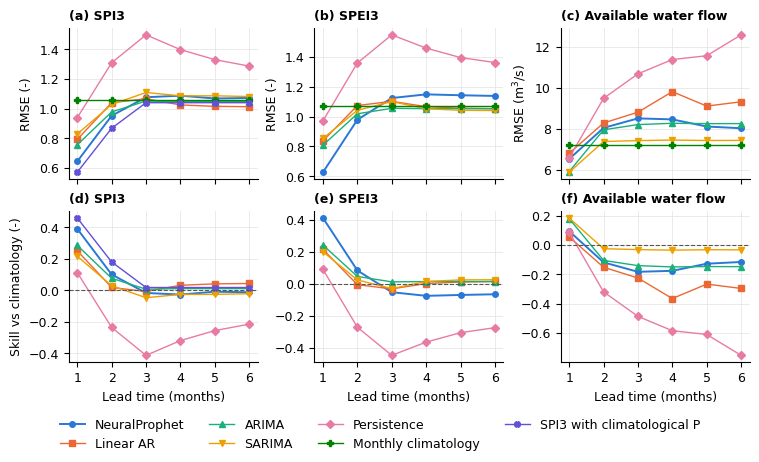

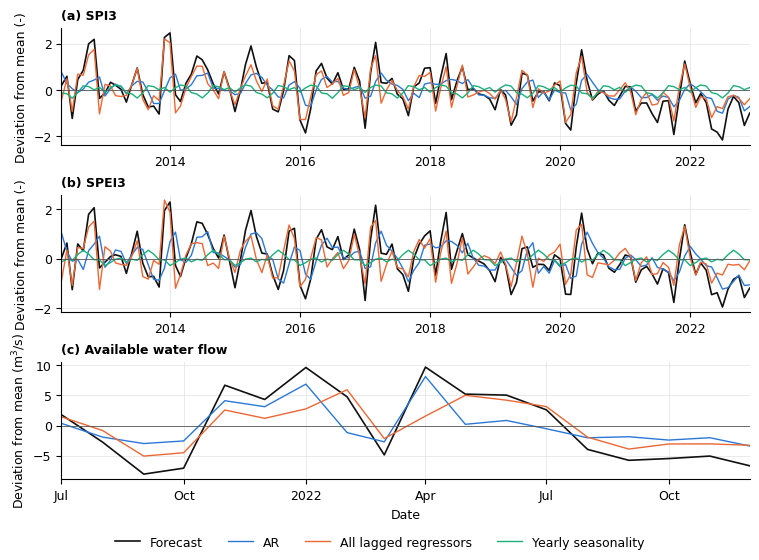

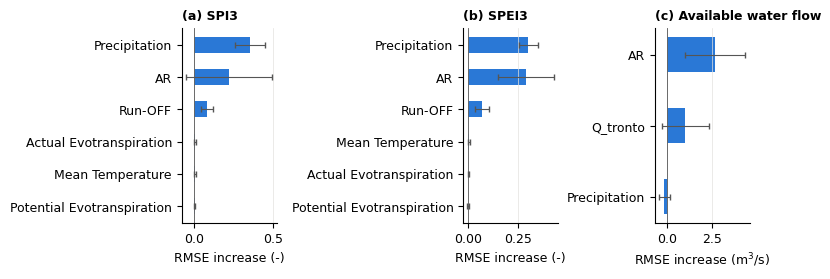

In [ ]:
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 9, 'axes.labelsize': 9, 'axes.titlesize': 9,
                     'xtick.labelsize': 9, 'ytick.labelsize': 9, 'legend.fontsize': 9, 'mathtext.fontset': 'dejavusans'})
cm = 1 / 2.54
NAMES = {'SPI3': 'SPI3', 'SPEI3': 'SPEI3', 'Q_Disp': 'Available water flow'}
TARGET_LIST = list(SPECS)


def save_figure(fig, name):
    fig.savefig(OUT / f'{name}.pdf', bbox_inches='tight')
    fig.savefig(OUT / f'{name}.png', dpi=300, bbox_inches='tight')
    plt.show()

fig, axes = plt.subplots(2, 3, figsize=(19 * cm, 11.5 * cm), constrained_layout=True, sharex=True)
for j, target in enumerate(TARGET_LIST):
    for method in LEAD_METHODS:
        g = lead_summary[(lead_summary.Target == target) & (lead_summary.Method == method)].sort_values('Lead')
        if g.empty:
            continue
        style = dict(color=LEAD_COLORS[method], marker=LEAD_MARKERS[method], ms=4, lw=1.4 if method == 'NeuralProphet' else 1.0, label=method)
        axes[0, j].plot(g.Lead, g.RMSE_mean, **style)
        if method != 'Monthly climatology':
            axes[1, j].plot(g.Lead, g.Skill_vs_climatology, **style)
    axes[1, j].axhline(0, color='#555555', lw=0.8, ls='--')
    axes[0, j].set_title(f"({'abc'[j]}) {NAMES[target]}", loc='left', fontweight='bold')
    axes[1, j].set_title(f"({'def'[j]}) {NAMES[target]}", loc='left', fontweight='bold')
    axes[0, j].set_ylabel('RMSE (m$^3$/s)' if target == 'Q_Disp' else 'RMSE (-)')
    axes[1, j].set_xlabel('Lead time (months)')
    axes[1, j].set_xticks(range(1, MAX_LEAD + 1))
    for ax in axes[:, j]:
        ax.grid(color='#E3E2DE', lw=0.5)
        ax.spines[['top', 'right']].set_visible(False)
axes[1, 0].set_ylabel('Skill vs climatology (-)')
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc='outside lower center', ncol=4, frameon=False)
save_figure(fig, 'Figure_skill_by_lead_time')

COMPONENT_STYLE = {'Forecast': ('#111111', 1.2), 'AR': ('#2a78d6', 1.0), 'All lagged regressors': ('#eb6834', 1.0),
                   'Yearly seasonality': ('#1baf7a', 1.0)}
fig, axes = plt.subplots(3, 1, figsize=(19 * cm, 14 * cm), constrained_layout=True)
mean_components = component_series.groupby(['Target', 'Component', 'ds'], as_index=False).Contribution.mean()
seen = {}
for j, (ax, target) in enumerate(zip(axes, TARGET_LIST)):
    data = mean_components[mean_components.Target == target]
    for name, (color, width) in COMPONENT_STYLE.items():
        g = data[data.Component == name].sort_values('ds')
        if len(g):
            seen[name], = ax.plot(g.ds, g.Contribution, color=color, lw=width, label=name)
    ax.axhline(0, color='#555555', lw=0.6)
    ax.set_xlim(data.ds.min(), data.ds.max())
    ax.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=9))
    ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(ax.xaxis.get_major_locator()))
    ax.set_ylabel('Deviation from mean (m$^3$/s)' if target == 'Q_Disp' else 'Deviation from mean (-)')
    ax.set_title(f"({'abc'[j]}) {NAMES[target]}", loc='left', fontweight='bold')
    ax.grid(color='#E3E2DE', lw=0.5)
    ax.spines[['top', 'right']].set_visible(False)
axes[-1].set_xlabel('Date')
fig.legend(seen.values(), seen.keys(), loc='outside lower center', ncol=4, frameon=False)
save_figure(fig, 'Figure_component_decomposition_test')

fig, axes = plt.subplots(1, 3, figsize=(19 * cm, 6.8 * cm), constrained_layout=True)
for j, (ax, target) in enumerate(zip(axes, TARGET_LIST)):
    g = importance_summary[importance_summary.Target == target].sort_values('Delta_RMSE_mean')
    ax.barh(g.Input, g.Delta_RMSE_mean, xerr=g.Delta_RMSE_sd, color='#2a78d6', height=0.5,
            error_kw=dict(ecolor='#555555', lw=0.8, capsize=2))
    ax.axvline(0, color='#555555', lw=0.6)
    ax.set_title(f"({'abc'[j]}) {NAMES[target]}", loc='left', fontweight='bold')
    ax.set_xlabel('RMSE increase (m$^3$/s)' if target == 'Q_Disp' else 'RMSE increase (-)')
    ax.grid(axis='x', color='#E3E2DE', lw=0.5)
    ax.spines[['top', 'right']].set_visible(False)
save_figure(fig, 'Figure_input_importance')
